# 🦵 RSNA Knee — v3: метки из заключений + окна по всем сериям + DINOv2 + зеркало

Это ваш ноутбук, переписанный шаг за шагом. Каждая ячейка начинается с объяснения **что** и
**зачем**, у каждого параметра в конфиге есть комментарий **на что он влияет**. Все комментарии в коде на русском.

## 🗺 Как пользоваться (порядок важен!)

1. **Сначала запустите только «Часть A — смотрим на данные»** (разделы 0–2, до заголовка «Часть B»).
   Это 2–5 минут. Посмотрите на картинки и таблицы и пришлите мне вывод: по нему решим, что настраивать.
2. Потом **Run All** с `FOLDS_TO_RUN = [0]` (один фолд, ~1.5–2.5 ч) и смотрите на `gold` в логе.
3. Если `gold` около 0.8 и выше, ставьте все фолды.

## 🔑 Почему ваш v1 стоял на 0.55 (коротко)

В `train.csv` 12 меток заполнены только у **58 из 4407** исследований, у остальных `NaN`.
`np.nan_to_num(labels, nan=0.0)` превращал 98.7% данных в «пациент полностью здоров».
Модель училась отвечать «0», а метрика на валидации была шумом. Настоящий источник меток —
текст заключения радиолога (колонка `Report`). В разделе 1 вы это увидите своими глазами.

## 📚 Откуда взяты идеи

| идея | откуда | зачем |
|---|---|---|
| метки из текста заключений (экстрактор на 9 языков) | `rsna-knee-baseline-v1` (~0.85) | без этого учиться не на чем |
| 6 серий-«слотов», кроп в миллиметрах, перцентили, EMA, ranking loss, фолды по тексту | `rsna-knee-baseline-v1` | физически осмысленный вход, стабильное обучение |
| **таблицы меток, прочитанных LLM** (если подключены) | ноутбук 0.958 (его модель на них: 0.929) | метки точнее регулярок → потолок выше |
| **58 размеченных — только для проверки**, в обучение не идут | ноутбук 0.958 | честная метрика на всех 58 в каждом фолде |
| **окна по всему стеку срезов (8–92%)**, а не только центр | ноутбук 0.958 | коллатеральные связки и латеральный мениск лежат на краях стека |
| **единая ориентация снимка** по `ImageOrientationPatient` | ноутбук 0.958 | разные сканеры кладут картинку по-разному |
| **зеркало колена** в обучении и на тесте (TTA) | ноутбук 0.958 | левое ↔ правое колено: вдвое больше «разных» примеров + усреднение |
| **внимание по всем окнам всех серий** (MIL) + маленький трансформер | ноутбук 0.958 | каждая патология сама выбирает нужные срезы |
| нет fat-sat серии → берём её пару без fat-sat (и наоборот) | ноутбук 0.958 | меньше пустых слотов |
| **проверка декодеров сжатых DICOM** | ноутбук 0.958 | в скрытом test есть сжатые файлы: без декодера → пустые снимки |

> Что в 0.958 **не** берём: сам результат 0.958 — это смесь чужих готовых моделей,
> обученных с внешними данными (OAI). Учиться на этом нельзя: можно только скопировать чужие веса.
> Мы строим **свою** модель по их рецепту.

---
# Часть A — смотрим на данные (запустите это первым)

## 0. Импорты и конфиг

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "4")      # чтобы numpy не дрался за ядра с потоками чтения DICOM

import gc
import re
import math
import time
import glob
import hashlib
import textwrap
import warnings
from copy import deepcopy
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
T0 = time.time()


def log(msg):
    # печать со временем от старта ноутбука: сразу видно, какой этап сколько занимает
    print(f"[{time.time() - T0:7.1f}s] {msg}", flush=True)


try:
    display                              # в Jupyter/Kaggle есть «красивый» вывод таблиц
except NameError:
    display = print

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
log(f"устройство: {DEV}, torch {torch.__version__}, timm {timm.__version__}, pydicom {pydicom.__version__}")

[    0.3s] устройство: cuda, torch 2.11.0+cu128, timm 1.0.29, pydicom 3.0.2


### Конфиг: все ручки в одном месте

**Правило:** меняйте **одну** ручку за раз и смотрите на `gold` в логе обучения. Если поменять три
сразу, не поймёте, какая помогла, а какая навредила.

In [2]:
SEED = 2026

# ---------------- Пути ----------------
DATA_DIR = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
if not DATA_DIR.exists():                       # на Kaggle путь бывает и без "competitions/"
    DATA_DIR = Path("/kaggle/input/rsna-knee-abnormality-detection")
WORK = Path("/kaggle/working")                  # сюда пишем веса фолдов и submission.csv
WORK.mkdir(parents=True, exist_ok=True)

# ---------------- Режим ----------------
RUN_TRAINING = True        # True — учим фолды; False — только предсказываем test готовыми весами
WEIGHTS_DIR = WORK / "weights"   # при RUN_TRAINING=False укажите путь к Kaggle-датасету с fold*.pth

# ---------------- Энкодер (2D-сеть, которая смотрит на одну картинку) ----------------
# DINOv2 ViT-S: 22M параметров, проверен в baseline-v1. Можно попробовать и другие из timm,
# например "convnext_tiny.fb_in22k" (CNN, как у лидеров) — но гиперпараметры для неё не проверены.
BACKBONE = "vit_small_patch14_dinov2.lvd142m"
# Путь к файлу весов (.pth), загруженному как Kaggle Dataset. Если файла нет — timm скачает
# веса сам, для этого в настройках ноутбука должен быть включён Internet.
WEIGHTS_PATH = "/kaggle/input/datasets/tihon2010/weights-vit-small-patch14-dinov2/vit_small_patch14_dinov2.pth"
UNFREEZE_LAST = 6          # сколько последних блоков ViT учится (из 12). Остальные заморожены:
                           # ранние блоки — общие «детекторы краёв», данных мало, испортить их легко.

# ---------------- Как готовим картинку ----------------
IMG = 224                  # сторона картинки на входе сети (кратна 14 — размер патча ViT)
CROP_MM = 140.0            # вырезаем квадрат 140×140 МИЛЛИМЕТРОВ вокруг центра → у всех
                           # исследований один физический масштаб (≈0.63 мм в пикселе при 224)
K_WIN = 4                  # сколько «окон» по 3 соседних среза берём из каждой серии
                           # (3 соседних среза = 3 канала, как RGB). 4 окна × 3 = 12 срезов на серию
WIN_BAND = (0.08, 0.92)    # где по стеку ставить окна: от 8% до 92% (края — мягкие ткани,
                           # но связки и латеральный мениск лежат близко к краям — центр мало!)
FILL_MISSING_SLOTS = True  # нет серии с fat-sat → подставить такую же плоскость без fat-sat (и наоборот)

# ---------------- Метки ----------------
USE_LLM_TABLES = True      # искать в /kaggle/input таблицы меток, прочитанных LLM (см. раздел 3.3)
GOLD_IN_TRAIN = False      # False: 58 размеченных НЕ участвуют в обучении → честная проверка

# ---------------- Модель (голова над энкодером) ----------------
HIDDEN = 256               # размер векторов в голове
TF_DEPTH = 1               # слоёв трансформера, через которые окна «переговариваются» (0 = выключить)

# ---------------- Обучение ----------------
N_FOLDS = 4                # фолды по хэшу текста заключения (раздел 7)
FOLDS_TO_RUN = [0]         # для первого запуска — один фолд; потом [0, 1, 2, 3]
EPOCHS = 10
BATCH_STUDIES = 8          # исследований в батче
K_TRAIN = 2                # окон на серию в КАЖДОМ шаге обучения (случайные из K_WIN):
                           # быстрее в 2 раза и работает как аугментация. На проверке — все K_WIN.
LR_BACKBONE = 8e-6         # энкодер только «подстраиваем»: большой LR разрушит предобучение
LR_HEAD = 5e-4             # голова учится с нуля → LR намного больше
WEIGHT_DECAY = 0.02
PCT_START = 0.15           # первые 15% шагов LR плавно растёт (разогрев), потом падает до нуля
EMA_DECAY = 0.997          # «скользящее среднее» весов, сглаживает шум (0 = выключить)
RANK_LOSS_W = 0.05         # вес ранжирующего лосса (напрямую тянет AUC вверх)
RANK_POS, RANK_NEG = 0.60, 0.40   # мягкая метка > 0.6 — «есть», < 0.4 — «нет» (для ranking loss)
USE_AMP = DEV.type == "cuda"      # смешанная точность float16: ~2× быстрее на GPU

# Аугментации: только то, что не меняет смысл метки (подробно в разделе 9)
AUG_ROT_DEG, AUG_SCALE, AUG_SHIFT = 10.0, 0.10, 0.06   # поворот ±10°, зум до +10%, сдвиг ±6%
AUG_GAMMA, AUG_GAIN = 0.25, 0.10                       # контраст (гамма) и яркость ±10%
MIRROR_P = 0.5             # с вероятностью 50% «зеркалим колено» (левое ↔ правое)
TTA_MIRROR = True          # на проверке/тесте усредняем обычный и зеркальный вид

# ---------------- Ресурсы ----------------
SERIES_THREADS = 24        # сколько серий читаем параллельно (упор в диск Kaggle, не в CPU)
EVAL_BATCH = 4             # исследований за раз при предсказании
CACHE_MAX_SHARE = 0.55     # кэш может занять не больше этой доли свободной памяти
TIME_BUDGET = 8.5 * 3600   # Kaggle даёт 9 ч на сабмит (12 ч на интерактивную сессию)

TARGETS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
           "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
           "Contusion", "Fracture"]


def seed_everything(seed):
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
log(f"DATA_DIR = {DATA_DIR} (существует: {DATA_DIR.exists()})")

[    0.3s] DATA_DIR = /kaggle/input/competitions/rsna-knee-abnormality-detection (существует: True)


In [ ]:
import fnmatch

def find_file(pattern, base="/kaggle/input"):
    # ищем файл по всем подключённым датасетам, не заходя в папки с DICOM (там сотни тысяч файлов)
    for root, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d not in ("train_series", "test_series")]
        for f in files:
            if fnmatch.fnmatch(f, pattern):
                return os.path.join(root, f)
    return None

BACKBONE = "vit_small_patch14_dinov2.lvd142m"
WEIGHTS_PATH = find_file("vit_small_patch14_dinov2*.pth")
assert WEIGHTS_PATH, "Веса не найдены: подключите датасет с vit_small_patch14_dinov2.pth в Input"
print("веса:", WEIGHTS_PATH)

## 1. Как выглядят данные

Пройдём сверху вниз: папки → таблицы → тексты → серии → один DICOM-файл → картинки.

### 1.1 Что лежит в папке соревнования

In [3]:
for p in sorted(DATA_DIR.iterdir()):
    if p.is_dir():
        n = sum(1 for _ in os.scandir(p))
        print(f"  📁 {p.name + '/':<20} {n:>6} папок (одна папка = одно исследование = один пациент-визит)")
    else:
        print(f"  📄 {p.name:<20} {p.stat().st_size / 1e6:>8.2f} МБ")

print('''
Структура:  train_series/<StudyInstanceUID>/<SeriesInstanceUID>/<много файлов .dcm>
            исследование          серия (одна «съёмка»)   один файл = один срез''')

  📄 sample_submission.csv     0.00 МБ
  📄 test.csv                 0.00 МБ
  📁 test_series/              3 папок (одна папка = одно исследование = один пациент-визит)
  📄 test_series.csv          0.00 МБ
  📄 train.csv                5.69 МБ
  📁 train_series/          4407 папок (одна папка = одно исследование = один пациент-визит)
  📄 train_series.csv         3.46 МБ

Структура:  train_series/<StudyInstanceUID>/<SeriesInstanceUID>/<много файлов .dcm>
            исследование          серия (одна «съёмка»)   один файл = один срез


### 1.2 `train.csv`: одна строка = одно исследование

Смотрите на колонки целей: сколько в них **пустых** значений. Это и есть главный вывод.

In [4]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
print("размер:", train_df.shape, "  колонки:", list(train_df.columns))
display(train_df.drop(columns=["Report"]).head(5))

gold_mask_df = train_df[TARGETS].notna().all(axis=1)      # True, если все 12 меток заполнены
print(f"\n👉 Исследований с РУЧНОЙ разметкой всех 12 меток: {int(gold_mask_df.sum())} из {len(train_df)}")
print(f"   У остальных {int((~gold_mask_df).sum())} метки пустые (NaN). В v1 они стали нулями — отсюда 0.55.\n")

cnt = pd.DataFrame({"заполнено": train_df[TARGETS].notna().sum(),
                    "пусто (NaN)": train_df[TARGETS].isna().sum(),
                    "доля «есть» среди размеченных": train_df.loc[gold_mask_df, TARGETS].mean().round(2)})
display(cnt)

размер: (4407, 14)   колонки: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



👉 Исследований с РУЧНОЙ разметкой всех 12 меток: 58 из 4407
   У остальных 4349 метки пустые (NaN). В v1 они стали нулями — отсюда 0.55.



,заполнено,пусто (NaN),доля «есть» среди размеченных
ACL,58,4349,0.41
MCL,58,4349,0.16
Medial Meniscus,58,4349,0.45
Lateral Meniscus,58,4349,0.40
Medial OA,58,4349,0.26
Lateral OA,58,4349,0.19
PF OA,58,4349,0.36
Effusion,58,4349,0.60
Synovitis,58,4349,0.47
Baker's,58,4349,0.21


### 1.3 Тексты заключений (`Report`) — настоящий источник меток

Заключения на разных языках (английский, испанский, турецкий, греческий, болгарский…).
Именно из них в разделе 3 мы сделаем метки для всех 4407 исследований.

In [5]:
rep = train_df["Report"].fillna("")
print(f"длина заключения в символах: медиана {int(rep.str.len().median())}, "
      f"min {rep.str.len().min()}, max {rep.str.len().max()}\n")

print("Начала 12 случайных заключений (видно, какие языки):")
for t in rep.sample(12, random_state=0):
    print("  •", t.replace("\n", " ")[:110])

print("\n" + "=" * 100)
ex = train_df[gold_mask_df].iloc[0]
print("Пример ПОЛНОГО заключения у размеченного исследования и его ручные метки:\n")
print(textwrap.fill(ex["Report"][:1500], 110))
print("\nручные метки:", {t: int(ex[t]) for t in TARGETS})

длина заключения в символах: медиана 977, min 52, max 4743

Начала 12 случайных заключений (видно, какие языки):
  • ΤΕΧΝΙΚΗ: Η εξέταση πραγµατοποιήθηκε µε ακολουθίες PD µε καταστολή του σήµατος του λίπους, Τ1 και Τ2*. ΕΥΡΗΜΑΤΑ
  • SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs anterior ve posterior ho
  • MRI ∆ΕΞΙΟΥ ΓΟΝΑΤΟΣ ΤΕΧΝΙΚΗ Η εξέταση έγινε µε ακολουθίες παλµών Τ1 και πυκνότητας πρωτονίων µε καταστολή του σ
  • SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs normaldir.  Medial menis
  • Antecedentes Clínicos: Síndrome meniscal medial. Hallazgos: No hay alteraciones de señal significativas de la 
  • FINDINGS:  Fluid: No joint effusion. No popliteal cyst. Small popliteal ganglion cyst.  Medial compartment (me
  • No evidence of knee effusion. Normal medial and lateral menisci. No evidence of tears.  Normal ACL, PCL, MCL a
  • Lig. iliotibiale postoperativ zunehmend verdickt von zuletzt 3 auf 6 mm (5/14)

### 1.4 `train_series.csv`: какие серии есть в каждом исследовании

Одно исследование = **несколько серий**: снимки в разных плоскостях
(сагиттальная — «сбоку», корональная — «спереди», аксиальная — «сверху»)
и в разных режимах (`Fat_Suppression` = 1 → жир подавлен, отёки и жидкость яркие).

In [6]:
train_series = pd.read_csv(DATA_DIR / "train_series.csv")
test_series = pd.read_csv(DATA_DIR / "test_series.csv")
print("размер:", train_series.shape, "  колонки:", list(train_series.columns))
display(train_series.head(6))

print("\nСколько серий каждой плоскости, с подавлением жира (1) и без (0):")
display(pd.crosstab(train_series["Anatomical_Plane"], train_series["Fat_Suppression"]))
if "Fluid_Sensitive" in train_series.columns:
    same = (train_series["Fat_Suppression"] == train_series["Fluid_Sensitive"]).mean()
    print(f"Fat_Suppression совпадает с Fluid_Sensitive в {same:.1%} строк (то есть это по сути один флаг)")

per_study = train_series.groupby("StudyInstanceUID").size()
print(f"\nсерий на исследование: в среднем {per_study.mean():.1f}, min {per_study.min()}, max {per_study.max()}")
combo = (train_series.assign(k=train_series["Anatomical_Plane"].str[:3] + train_series["Fat_Suppression"].map({1: "+FS", 0: ""}))
         .groupby("StudyInstanceUID")["k"].apply(lambda s: " ".join(sorted(s))))
print("\nСамые частые наборы серий в исследовании:")
display(combo.value_counts().head(8).rename("исследований").to_frame())

размер: (24371, 5)   колонки: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal
5,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.27845969797953115400...,0,0,Sagittal



Сколько серий каждой плоскости, с подавлением жира (1) и без (0):


Fat_Suppression,0,1
Anatomical_Plane,,
Axial,1179,4719
Coronal,3985,4624
Sagittal,5197,4667


Fat_Suppression совпадает с Fluid_Sensitive в 100.0% строк (то есть это по сути один флаг)

серий на исследование: в среднем 5.5, min 3, max 14

Самые частые наборы серий в исследовании:


,исследований
k,
Axi+FS Cor Cor+FS Sag Sag+FS,1747
Axi+FS Cor+FS Sag Sag+FS,475
Axi+FS Cor Cor Cor+FS Sag Sag+FS,290
Axi+FS Cor+FS Sag Sag+FS Sag+FS,228
Axi Axi+FS Cor+FS Sag Sag,203
Axi Axi Axi+FS Cor Cor+FS Sag Sag+FS,166
Axi+FS Cor Sag Sag+FS,104
Axi+FS Axi+FS Cor Cor+FS Sag Sag+FS,104


### 1.5 Одно исследование изнутри

In [7]:
STUDY = train_df.loc[gold_mask_df, "StudyInstanceUID"].iloc[0]   # берём размеченное, чтобы видеть метки
ser = train_series[train_series["StudyInstanceUID"] == STUDY]
print(f"Исследование {STUDY}")
for r in ser.itertuples():
    d = DATA_DIR / "train_series" / STUDY / str(r.SeriesInstanceUID)
    n = len([f for f in os.listdir(d) if f.endswith(".dcm")]) if d.is_dir() else 0
    print(f"  └─ серия …{str(r.SeriesInstanceUID)[-12:]}  {r.Anatomical_Plane:<9} "
          f"fat-sat={r.Fat_Suppression}  файлов(срезов): {n}")

Исследование 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
  └─ серия …517371931282  Sagittal  fat-sat=0  файлов(срезов): 36
  └─ серия …854063726441  Coronal   fat-sat=0  файлов(срезов): 30
  └─ серия …928971904198  Coronal   fat-sat=1  файлов(срезов): 30
  └─ серия …109474719429  Sagittal  fat-sat=1  файлов(срезов): 36
  └─ серия …529101229430  Axial     fat-sat=1  файлов(срезов): 32


### 1.6 Один DICOM-файл: что внутри

DICOM = картинка + «заголовок» с сотнями тегов. Нам важны:
- `ImagePositionPatient` — где в теле пациента (в мм) лежит угол этого среза;
- `ImageOrientationPatient` — как повёрнута плоскость среза;
- `PixelSpacing` — сколько миллиметров в одном пикселе;
- `TransferSyntaxUID` — сжат ли файл (для сжатых нужны отдельные декодеры).

In [8]:
r0 = ser.iloc[0]
d0 = DATA_DIR / "train_series" / STUDY / str(r0.SeriesInstanceUID)
f0 = sorted(os.listdir(d0))[0]
ds = pydicom.dcmread(d0 / f0)
for tag in ["Manufacturer", "SeriesDescription", "Rows", "Columns", "PixelSpacing", "SliceThickness",
            "ImagePositionPatient", "ImageOrientationPatient", "InstanceNumber",
            "RepetitionTime", "EchoTime", "PhotometricInterpretation", "BitsStored", "Laterality"]:
    print(f"  {tag:<26} {getattr(ds, tag, '— нет —')}")
print(f"  {'TransferSyntaxUID':<26} {ds.file_meta.TransferSyntaxUID} ({ds.file_meta.TransferSyntaxUID.name})")
a = ds.pixel_array
print(f"\npixel_array: форма {a.shape}, тип {a.dtype}, min {a.min()}, max {a.max()}, среднее {a.mean():.1f}")
print("Значения НЕ 0..255: у МРТ нет «абсолютной» яркости, поэтому нормализуем каждую серию (раздел 5).")

  Manufacturer               Siemens Healthineers
  SeriesDescription          t2_tse_sag
  Rows                       400
  Columns                    400
  PixelSpacing               [0.4, 0.4]
  SliceThickness             2.5
  ImagePositionPatient       [-107.749, -142.03, 87.0285]
  ImageOrientationPatient    [-0.0703243, 0.987791, 0.139011, -0.109147, 0.130899, -0.985369]
  InstanceNumber             14
  RepetitionTime             6570
  EchoTime                   75
  PhotometricInterpretation  MONOCHROME2
  BitsStored                 12
  Laterality                 R
  TransferSyntaxUID          1.2.840.10008.1.2.1 (Explicit VR Little Endian)

pixel_array: форма (400, 400), тип uint16, min 0, max 753, среднее 191.4
Значения НЕ 0..255: у МРТ нет «абсолютной» яркости, поэтому нормализуем каждую серию (раздел 5).


### 1.7 Как выглядят серии одного исследования (средний срез каждой)

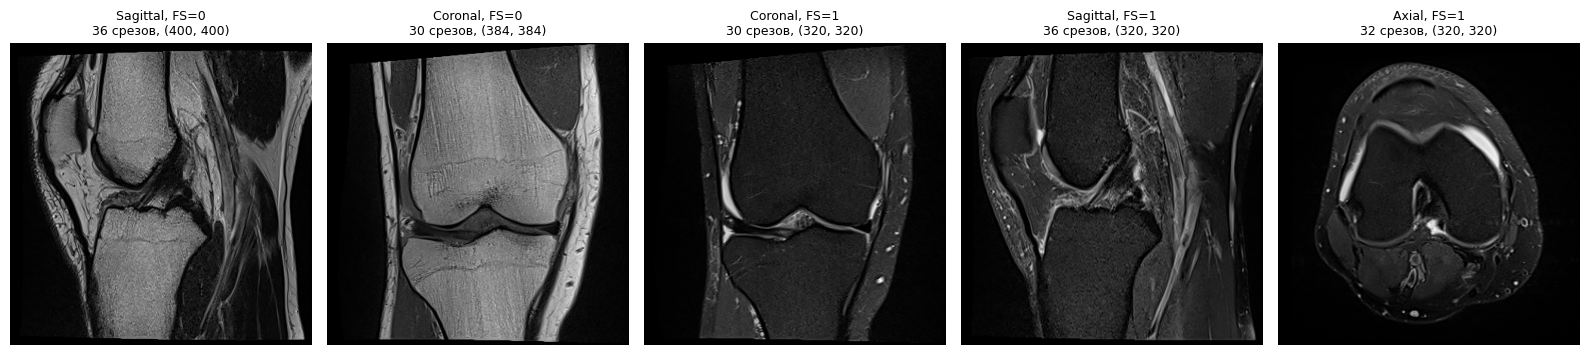

In [9]:
def header_pos(path):
    # координата среза вдоль нормали к его плоскости (подробно — в разделе 5)
    h = pydicom.dcmread(path, stop_before_pixels=True, force=True)
    iop = np.array(h.ImageOrientationPatient, float)
    return float(np.dot(np.array(h.ImagePositionPatient, float), np.cross(iop[:3], iop[3:])))


fig, axes = plt.subplots(1, len(ser), figsize=(3.2 * len(ser), 3.6))
axes = np.atleast_1d(axes)
for ax, r in zip(axes, ser.itertuples()):
    d = DATA_DIR / "train_series" / STUDY / str(r.SeriesInstanceUID)
    files = sorted(d.glob("*.dcm"), key=header_pos)
    img = pydicom.dcmread(files[len(files) // 2]).pixel_array
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{r.Anatomical_Plane}, FS={r.Fat_Suppression}\n{len(files)} срезов, {img.shape}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

### 1.8 Почему важен ПОРЯДОК срезов

Имена файлов — это случайные идентификаторы (UID). Если сортировать по имени, срезы идут
вразнобой (верхний ряд). Правильно сортировать по положению в теле (нижний ряд).
В v1 сортировали по `ImagePositionPatient[2]` (высота). Для сагиттальной серии это бессмысленно:
там срезы сдвигаются не по высоте, а слева направо.

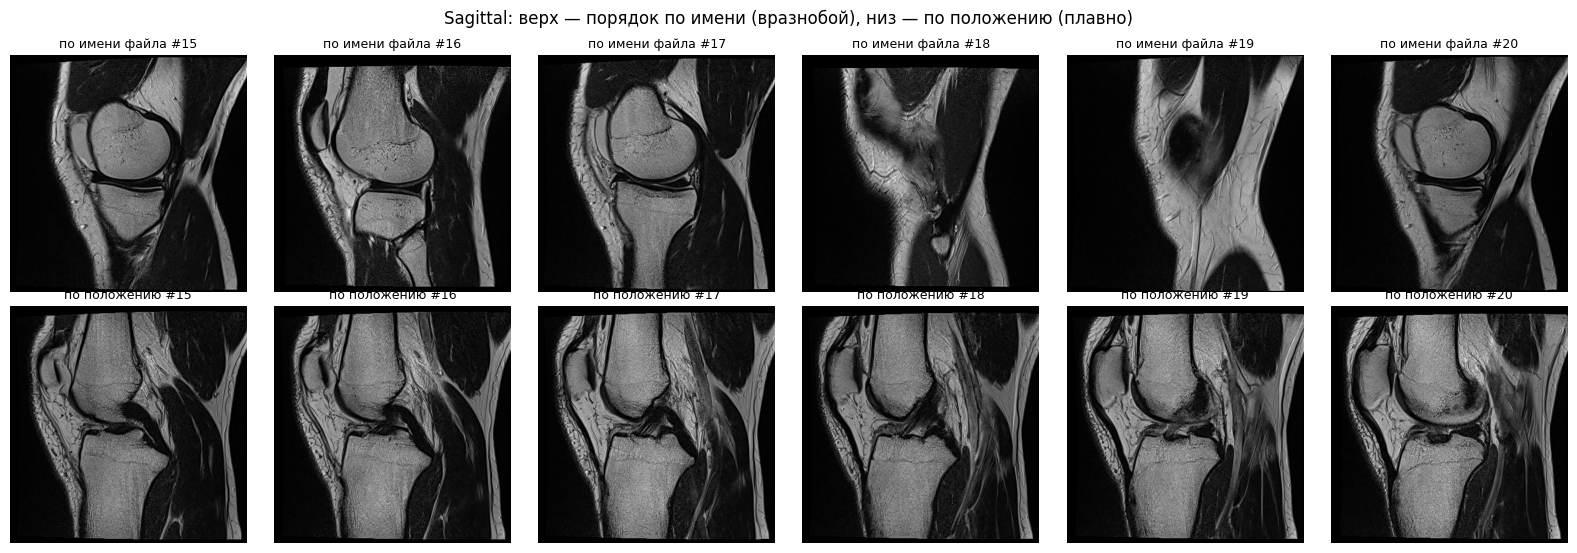

In [10]:
sag = ser[ser["Anatomical_Plane"] == "Sagittal"]
r = (sag if len(sag) else ser).iloc[0]
d = DATA_DIR / "train_series" / STUDY / str(r["SeriesInstanceUID"])
by_name = sorted(d.glob("*.dcm"))
by_pos = sorted(by_name, key=header_pos)
mid = len(by_pos) // 2
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for j in range(6):
    axes[0, j].imshow(pydicom.dcmread(by_name[mid - 3 + j]).pixel_array, cmap="gray")
    axes[0, j].set_title(f"по имени файла #{mid - 3 + j}", fontsize=9)
    axes[1, j].imshow(pydicom.dcmread(by_pos[mid - 3 + j]).pixel_array, cmap="gray")
    axes[1, j].set_title(f"по положению #{mid - 3 + j}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle(f"{r['Anatomical_Plane']}: верх — порядок по имени (вразнобой), низ — по положению (плавно)")
plt.tight_layout(); plt.show()

### 1.9 Размер пикселя и поле зрения сильно различаются

Если просто сделать `resize(224)`, у одного пациента колено займёт весь кадр, у другого половину.
Поэтому режем квадрат **в миллиметрах** (`CROP_MM`), а уже потом меняем размер.

,срезов,мм/пиксель,пикселей,"поле зрения, мм"
count,150.00,150.00,150.00,150.00
mean,34.57,0.36,531.07,164.86
std,30.44,0.14,206.36,14.75
min,18.00,0.14,192.00,130.00
25%,26.00,0.25,384.00,160.00
50%,30.00,0.34,512.00,160.00
75%,33.00,0.42,640.00,170.01
max,320.00,0.89,1024.00,230.00


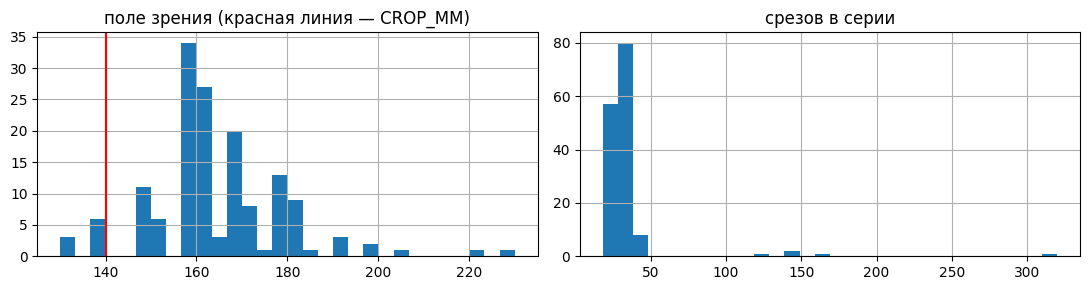

In [11]:
rows = []
for r in train_series.sample(min(150, len(train_series)), random_state=0).itertuples():
    d = DATA_DIR / "train_series" / str(r.StudyInstanceUID) / str(r.SeriesInstanceUID)
    fs = [f for f in os.listdir(d) if f.endswith(".dcm")] if d.is_dir() else []
    if not fs:
        continue
    h = pydicom.dcmread(d / fs[0], stop_before_pixels=True, force=True)
    ps = float(h.PixelSpacing[0]) if "PixelSpacing" in h else np.nan
    rows.append({"плоскость": r.Anatomical_Plane, "срезов": len(fs), "мм/пиксель": ps,
                 "пикселей": int(h.Rows), "поле зрения, мм": int(h.Rows) * ps})
geo = pd.DataFrame(rows)
display(geo.describe().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
geo["поле зрения, мм"].hist(ax=ax[0], bins=30); ax[0].axvline(CROP_MM, color="r"); ax[0].set_title("поле зрения (красная линия — CROP_MM)")
geo["срезов"].hist(ax=ax[1], bins=30); ax[1].set_title("срезов в серии")
plt.tight_layout(); plt.show()

### 1.10 Test

Видимый `test.csv` крошечный (несколько исследований). При сабмите Kaggle **перезапускает весь
ноутбук** на скрытом test, где исследований примерно 30% от train. Поэтому код не должен зависеть
от размера test, а train-часть лучше учить заранее (см. раздел 13).

In [12]:
test_df = pd.read_csv(DATA_DIR / "test.csv")
print("test.csv:", test_df.shape, list(test_df.columns))
print("test_series.csv:", test_series.shape)
display(test_df.head())

test.csv: (3, 1) ['StudyInstanceUID']
test_series.csv: (15, 5)


,StudyInstanceUID
0,1.2.826.0.1.3680043.8.498.10047035057544427318...
1,1.2.826.0.1.3680043.8.498.10062861783145312629...
2,1.2.826.0.1.3680043.8.498.10067514707072572280...


## 2. Декодеры сжатых DICOM (ловушка скрытого test)

Часть DICOM-файлов хранится **сжатой** (JPEG, JPEG-2000, JPEG-LS). Сам `pydicom` такие
картинки распаковать не может: нужны пакеты `pylibjpeg*` или `python-gdcm`. Автор ноутбука 0.958
пишет, что в **скрытом** test сжатые файлы есть. Без декодера каждый такой срез тихо
превращается в «нечитаемый» → пустая серия → плохое предсказание.

Ячейка ниже:
1. показывает, какие декодеры установлены;
2. если среди подключённых датасетов есть `.whl`-файлы декодеров, ставит их **без интернета**;
3. проверяет 200 случайных файлов: сколько из них сжато и читаются ли они.

In [13]:
import importlib, subprocess, sys

def have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

wheels = [w for pat in ("/kaggle/input/*/*.whl", "/kaggle/input/*/*/*.whl", "/kaggle/input/*/*/*/*.whl")
          for w in glob.glob(pat) if re.search(r"pylibjpeg|gdcm|jpegls", os.path.basename(w), re.I)]
if wheels:
    print("нашёл колёса декодеров в подключённых датасетах — ставлю офлайн:")
    for w in wheels:
        print("  ", w)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-index", "--no-deps"] + wheels, check=False)

for m in ["pylibjpeg", "libjpeg", "openjpeg", "jpeg_ls", "gdcm"]:
    print(f"  декодер {m:<10} {'✅ есть' if have(m) else '❌ нет'}")

rng = np.random.RandomState(0)
sample = []
for split, df_ in (("train_series", train_series), ("test_series", test_series)):
    for r in df_.sample(min(100, len(df_)), random_state=0).itertuples():
        d = DATA_DIR / split / str(r.StudyInstanceUID) / str(r.SeriesInstanceUID)
        fs = [f for f in os.listdir(d) if f.endswith(".dcm")] if d.is_dir() else []
        if fs:
            sample.append(d / fs[rng.randint(len(fs))])
n_comp = n_fail = 0
kinds = {}
for p in sample:
    try:
        ds_ = pydicom.dcmread(p)
        ts = ds_.file_meta.TransferSyntaxUID
        kinds[ts.name] = kinds.get(ts.name, 0) + 1
        if ts.is_compressed:
            n_comp += 1
        ds_.pixel_array
    except Exception:
        n_fail += 1
print(f"\nпроверено {len(sample)} файлов: сжатых {n_comp}, НЕ прочитались {n_fail}")
print("форматы:", kinds)
if n_fail:
    print("⚠️ Есть нечитаемые файлы. Подключите датасет с декодерами (например, тот, что использует "
          "ноутбук 0.958: goodpjw2008/rsna-knee-2-5d-convnext-reader) и перезапустите эту ячейку.")

  декодер pylibjpeg  ❌ нет
  декодер libjpeg    ❌ нет
  декодер openjpeg   ❌ нет
  декодер jpeg_ls    ❌ нет
  декодер gdcm       ❌ нет

проверено 115 файлов: сжатых 0, НЕ прочитались 0
форматы: {'Explicit VR Little Endian': 115}


---
# ✋ Конец части A

Пришлите вывод разделов 1–2 (таблицы и картинки), по нему проверим, что всё читается.
Дальше идёт часть B: метки → кэш → обучение → сабмит.

---
# Часть B — метки, кэш, модель, обучение

## 3. Метки из текстов заключений

### Идея
Для каждой из 12 патологий экстрактор на регулярных выражениях читает заключение по фразам и решает:
- фраза **утверждает** находку («complete tear of the ACL»);
- **отрицает** её («ACL intact», «sin derrame»);
- **сомневается** («possible tear»);
- или **молчит**.

### Шкала (мягкие метки, а не 0/1)

| что сказано | score | вес примера `W = 0.25 + 0.75·уверенность` |
|---|---|---|
| утверждение «large/marked» | до 0.95 | высокий |
| утверждение без уточнения | ~0.85 | высокий |
| «small/trace» | ~0.72 | высокий |
| сомнение | ~0.63 | средний |
| **тишина** | **0.28** | **≈0.29** (почти не влияет на обучение) |
| отрицание | 0.04–0.20 | средний/высокий |

**Почему не 0/1.** Метрика AUC смотрит только на **порядок** чисел. Радиолог в тексте и разметчик
используют разные пороги («небольшой выпот» разметчик мог пометить как 0). Мягкая шкала сохраняет
порядок «точно есть > возможно > не сказано > точно нет» и не навязывает порог.

Следующие 6 ячеек — экстрактор. Вникать в каждую регулярку не нужно. Достаточно понимать:
`extract(текст)` → `{"ACL": 0.85, "ACL__conf": 0.7, …}`.

In [14]:
# Ячейка 1/6 экстрактора: нормализация текста и разбиение на фразы
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения — без изменений; комментарии переведены и упрощены.

# Модули: re — регулярные выражения, unicodedata — работа с диакритикой (é → e)
import re
import unicodedata

# 12 целей соревнования — в этом порядке идут колонки и в train.csv, и в submission
TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]


# Таблица замен ДО перевода в нижний регистр.
# Турецкие İ/ı иначе превращаются в странные символы, и "İZLENMEZ" ≠ "izlenmez".
# Плюс немецкая ß, хорватская đ, датские ø/æ.
_PRE = str.maketrans({
    "ı": "i", "İ": "i", "I": "i", "ß": "ss", "đ": "d", "Đ": "d",
    "ø": "o", "Ø": "o", "æ": "ae", "Æ": "ae",
})


# normalize(текст) → текст в «удобной для регулярок» форме:
# - нижний регистр, без диакритики (греческое ά → α, é → e);
# - MICRO SIGN µ (U+00B5) → настоящая греческая μ (в греческих отчётах путают);
# - дефисы/слэши/подчёркивания → пробелы, лишние пробелы схлопнуты.
def normalize(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.translate(_PRE).lower()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    # мягкий перенос (невидимый символ) — удаляем
    text = text.replace("­", "")
    text = re.sub(r"[_\-/\\]+", " ", text)
    text = re.sub(r"[ \t]+", " ", text)
    return text


# Разбиение на фразы: после . ; ! ? или по переводу строки
_SENT_SPLIT = re.compile(r"(?<=[.;!?])\s+|\n+")


# clauses(текст) → список фраз.
# Важная хитрость: строка-заголовок вида "Fractures :" склеивается со следующей "Aucune."
# («Переломы: нет»). Если их не склеить, заголовок «Fractures» без отрицания
# прочитается как «перелом есть».
def clauses(text: str):
    norm = normalize(text)
    raw = [c.strip() for c in _SENT_SPLIT.split(norm) if c and c.strip()]

    merged = []
    for i, c in enumerate(raw):
        # Фраза кончается двоеточием и короткая (≤14 слов) → это заголовок,
        # приклеиваем к нему следующую фразу. Сам заголовок отдельно НЕ оставляем.
        if c.endswith(":") and len(c.split()) <= 14 and i + 1 < len(raw):
            merged.append(c + " " + raw[i + 1])
        else:
            merged.append(c)
    # Длинные перечисления через запятую (>25 слов) дополнительно режем по запятым
    out = []
    for c in merged:
        out.append(c)
        if len(c.split()) > 25:
            out.extend(p.strip() for p in c.split(",") if len(p.split()) > 2)
    return out


# _rx('a', 'b', ...) → одна скомпилированная регулярка 'a|b|...' (любой из вариантов)
def _rx(*alts: str) -> re.Pattern:
    return re.compile("|".join(alts))

In [15]:
# Ячейка 2/6 экстрактора: словари «как сказано» — отрицание, норма, сомнение, патология
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения — без изменений; комментарии переведены и упрощены.

# === Словари «как сказано» (для всех 9 языков сразу) ===
# NEGATION — слова отрицания: no, sin, pas de, geen, kein, yok, nema, δεν, без …
# Если отрицание есть во фразе → находка «отрицается».
NEGATION = _rx(
    # английский
    r"\bno\b", r"\bnot\b", r"\bwithout\b", r"\bnegative for\b", r"\babsence\b",
    r"\bno evidence\b", r"\bunremarkable\b", r"\bfree of\b", r"\bnone\b", r"\bnil\b",
    # испанский
    r"\bsin\b", r"\bno hay\b", r"\bausencia\b", r"\bausentes?\b",
    # французский
    r"\bpas de\b", r"\bsans\b", r"\baucune?\b", r"\babsence\b",
    # нидерландский
    r"\bgeen\b", r"\bzonder\b", r"\bniet\b",
    # немецкий
    r"\bkeine?\b", r"\bohne\b", r"\bnicht\b",
    # турецкий
    r"\byok\b", r"\byoktur\b", r"izlenmemekte", r"saptanmadi", r"\bdegil\b",
    r"gozlenmemekte", r"mevcut degil", r"eslik etmiyor", r"\bizlenmedi\b",
    # хорватский / сербский / боснийский
    r"\bnema\b", r"\bbez\b", r"\bnisu\b", r"\bnije\b",
    # греческий (ударения уже сняты normalize)
    r"\bδεν\b", r"\bχωρις\b", r"ουδεν",
    # болгарский / русский
    r"\bбез\b", r"\bне\b", r"липсва", r"\bняма\b",
)

# NORMALITY — «норма»: normal, intact, preserved, conservado, φυσιολογικ …
# «Связки в норме» = доказательство отсутствия находки (а не просто молчание).
NORMALITY = _rx(
    r"\bnormal", r"\bintact\b", r"\bpreserved\b", r"\bwithin normal limits\b",
    r"limites normales", r"\bconservad", r"\bintegr", r"\bnormales\b",
    r"\bdoga(l|ll)\b", r"korunmus", r"\bnormaldir\b", r"olagan",
    r"\buredn", r"\bocuvan", r"\bodrzan", r"\bintakt",
    r"φυσιολογικ", r"ακεραι",
    r"unauffallig", r"regelrecht", r"\bintakt\b",
    r"нормал", r"запазен", r"съхранен", r"\bбез особености\b",
    r"\bgaaf\b", r"\bnormaal\b",
)

# UNCERTAIN — сомнение: possible, suspected, cannot exclude, πιθαν …
UNCERTAIN = _rx(
    r"\bpossible\b", r"\bprobable\b", r"\bsuspicious\b", r"\bsuspected\b",
    r"cannot (be )?exclude", r"\bmay\b", r"\bquestionable\b", r"\bequivocal\b",
    r"\bposible\b", r"sin criterios categoricos", r"\bdudos",
    r"\bmuhtemel\b", r"\bolasi\b", r"\bsupheli\b", r"\bizlenim",
    r"\bmoguce\b", r"\bvjerojatno\b", r"\bsumnja\b",
    r"πιθαν", r"υποπτ",
    r"\bmoglich", r"\bverdachtig", r"\bfraglich", r"\bV\.a\.\b",
    r"\bвъзможно\b", r"\bвероятно\b", r"суспект",
    r"\bmogelijk\b", r"\bverdacht\b",
)

# === Словари патологии (используются для связок и менисков) ===
# TEAR — разрыв: tear, rupture, rotura, déchirure, Riss, yırtık, ρηξη, руптура …
TEAR = _rx(
    r"\btear", r"\btorn\b", r"\brupture", r"\bdisruption\b", r"discontinuit",
    r"\bavuls",
    r"\brotura\b", r"\broturas\b", r"\bruptura", r"\bdesgarro", r"\broto\b",
    r"\bdechirure", r"\bdechire",
    r"\bscheur", r"\bruptuur", r"gescheurd",
    r"riss(bildung|e|es)?\b", r"einriss", r"\bruptur", r"zerreiss", r"\blasion",
    r"\byirtik", r"\byirtig", r"\bkopma\b", r"butunluk kaybi", r"\brupturu\b",
    r"\bpuknuce", r"\bruptur", r"\bprekid\b", r"\bpukotin",
    r"ρηξη", r"ρηξις", r"ρηγμα",
    r"руптура", r"разкъсв", r"разрив", r"скъсв",
)

# DEGEN — дегенерация: degenerat, mucoid, fray, fissur …
DEGEN = _rx(
    r"degenerat", r"\bmucoid\b", r"\bmyxoid\b", r"\bfray", r"\bfissur",
    r"dejeneratif", r"\bmukoid\b", r"degenerativn", r"εκφυλ", r"дегенерат",
    r"\bμυξοειδ", r"\bμυξωδ",
    r"\bmuco ?ide\b", r"aufgefasert",
)

# INJURY — повреждение/отёк/сигнал: injury, sprain, edema, high signal, partial …
INJURY = _rx(
    r"\binjur", r"\bsprain", r"\blesion", r"\blasion", r"\bedema\b", r"\boedema\b",
    r"\bodem\b", r"\bedem\b", r"\bοιδημα", r"\bодем", r"\bедем", r"\bstrain\b",
    r"\bhigh signal\b", r"\bsignal alteration\b", r"\bhiperintens", r"\bhyperintens",
    r"aumento de senal", r"alteracion de senal", r"cambio de senal",
    r"\bsignalanhebung", r"\bsignalalteration", r"verhoogd signaal", r"sinyal artis",
    r"αυξημενο σημα", r"повишен сигнал",
    r"\bthicken", r"\bzadebljanje\b", r"\bverdikking\b", r"\bdistenzij",
    r"\blaksite\b", r"\blaxity\b", r"\bpartial\b", r"\bparcijaln", r"\bparcial",
    r"\bpartiel", r"\bpartiell",
)

In [16]:
# Ячейка 3/6 экстрактора: словари анатомии, остеоартрита и «самоназывающих» находок
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения — без изменений; комментарии переведены и упрощены.

# === Анатомия: для 4 «парных» целей (ACL, MCL, медиальный/латеральный мениск) ===
# Находка засчитывается, только если во фразе есть И анатомия (этот словарь),
# И патология (TEAR/DEGEN/INJURY из прошлой ячейки).
ANAT = {
    # передняя крестообразная связка
    "ACL": _rx(
        r"anterior cruciate", r"\bacl\b",
        r"cruzado anterior", r"\blca\b",
        r"croise anterieur",
        r"voorste kruisband", r"\bvkb\b",
        r"vorderes kreuzband", r"vorderen kreuzband", r"vordere kreuzband",
        r"on capraz", r"\bocb\b",
        r"prednji krizni", r"prednjeg krizn",
        r"προσθι[οα][^ ]* χιαστ", r"προσθιου χιαστου", r"χιαστο[^ ]* συνδεσμ",
        # греческий отделяет прилагательное от существительного
        # ("χιαστοι και πλαγιοι συνδεσμοι"), поэтому основа «χιαστ» стоит отдельно
        r"\bχιαστ\w*",
        r"предна кръстна", r"предната кръстна",
        # множественное число без стороны: «крестообразные связки в норме»
        # очищает сразу обе связки — без этих форм фраза терялась
        r"cruciate ligaments", r"ligamentos cruzados", r"ligaments croises",
        r"kruisbanden", r"kreuzbander", r"capraz baglar", r"krizn[a-z]* ligament[a-z]*",
        r"χιαστοι συνδεσμ", r"χιαστων συνδεσμ", r"кръстните връзки", r"кръстни връзки",
    ),
    # медиальная коллатеральная связка
    "MCL": _rx(
        r"medial collateral", r"\bmcl\b", r"tibial collateral",
        r"colateral medial", r"colateral interno", r"\blcm\b",
        r"collateral medial", r"collateral interne",
        r"mediale collaterale", r"binnenband", r"\b(mediale|laterale) banden\b",
        r"\bcollaterale banden\b",
        r"innenband", r"mediales? kollateral",
        r"\bic yan bag", r"medial kollateral", r"\biyb\b",
        r"medijalni kolateraln", r"medijalnog kolateraln",
        r"εσω πλαγι", r"εσωτερικο πλαγι", r"\bπλαγι\w* συνδεσμ", r"\bπλαγιοι\b",
        r"медиален колатерал", r"вътрешна странична", r"\bколатерал\w*",
        # то же для коллатеральных: «cruzados y colaterales» — прилагательное отдельно
        r"\bcolaterales\b", r"\bcollateraux\b", r"\bcollateralen\b", r"\bkolateralni\b",
        r"collateral ligaments", r"ligamentos colaterales", r"ligaments collateraux",
        r"collaterale banden", r"kollateralbander", r"seitenbander", r"yan baglar",
        r"kolateraln[a-z]* ligament[a-z]*", r"πλαγιοι συνδεσμ", r"πλαγιων συνδεσμ",
        r"колатерални връзки", r"страничните връзки",
    ),
    # медиальный мениск
    "Medial Meniscus": _rx(
        r"medial meniscus", r"\bmm\b(?= tear)", r"medial menisc",
        r"menisco medial", r"menisco interno",
        r"menisque medial", r"menisque interne",
        r"mediale meniscus", r"binnenmeniscus",
        r"innenmeniskus", r"medialen? meniskus", r"innenmeniskushinterhorn",
        r"medyal menisk", r"\bic menisk",
        r"medijalni meniskus", r"medijalnog meniskusa", r"medijalnom meniskusu",
        r"εσω μηνισκ", r"μηνισκ[^ ]* του εσω", r"εσω διαμερισμα[^.]{0,40}μηνισκ",
        r"медиалния менискус", r"медиален менискус", r"вътрешния менискус",
    ),
    # латеральный мениск
    "Lateral Meniscus": _rx(
        r"lateral meniscus", r"lateral menisc",
        r"menisco lateral", r"menisco externo",
        r"menisque lateral", r"menisque externe",
        r"laterale meniscus", r"buitenmeniscus",
        r"aussenmeniskus", r"lateralen? meniskus",
        r"lateral menisk", r"\bdis menisk",
        r"lateralni meniskus", r"lateralnog meniskusa", r"lateralnom meniskusu",
        r"εξω μηνισκ", r"μηνισκ[^ ]* του εξω", r"εξω διαμερισμα[^.]{0,40}μηνισκ",
        r"латералния менискус", r"латерален менискус", r"външния менискус",
    ),
}

# === Остеоартрит (OA) ===
# Слово «артроз» пишут редко. Пишут: хондропатия, потеря хряща, остеофиты,
# сужение суставной щели — это и есть признаки OA.
OA_EVIDENCE = _rx(
    r"osteoarthrit", r"\barthros", r"\bgonarthros", r"\bosteoarthros",
    r"chondropath", r"chondromalac", r"condropat", r"condromalac",
    r"cartilage loss", r"cartilage thinning", r"chondral (loss|defect|ulcer|thinning)",
    r"osteophyt", r"osteofit", r"osteofyt", r"osteofito", r"osteophyten",
    r"joint space narrowing", r"pinzamiento articular",
    r"kikirdak kayb", r"kikirdak incelme", r"kondropati", r"kondral",
    r"kraakbeen(lijden|verlies)", r"gonartrose", r"artrose",
    r"knorpel(verlust|schaden|defekt)", r"arthrose", r"gonarthrose",
    r"hrskavic", r"hondromalac", r"artroz", r"osteoartrit",
    r"χονδρ[^ ]*παθ", r"αρθριτ", r"αρθρωσ", r"οστεοφυτ",
    r"αρθρικου χονδρου", r"εξαλειψη του αρθρικου χονδρου",
    r"артроз", r"хондропат", r"остеофит", r"хрущял[^.]{0,30}(изтън|увред|дефект)",
    r"ulcera[s]? condral", r"cartilago[^.]{0,25}(perdida|adelgaz)",
    r"icrs grade", r"outerbridge",
)

# Отделы сустава: медиальный, латеральный, пателлофеморальный (PF).
# OA-цель = признак OA (выше) + упоминание отдела (здесь) в одной фразе.
COMPARTMENT = {
    "Medial OA": _rx(
        r"medial (femorotibial|tibiofemoral|compartment)",
        r"compartimento femorotibial medial", r"femorotibial interno",
        r"mediaal femorotibiaal", r"mediale femorotibial",
        r"medial femorotibial", r"medialen kompartiment", r"innere[sn]? kompartiment",
        r"medyal femorotibial", r"ic kompartman", r"medyal kompartman",
        r"medijaln[^ ]* (femorotibi|odjelj|kompartm)",
        r"εσω διαμερισμα", r"εσω κνημιαι", r"εσω μηριαι",
        r"медиалн[^ ]* (компартм|отдел|тибиал|феморотиб)",
        r"medial (femoral|tibial) (condyle|plateau)", r"condilo femoral medial",
        r"medialen? (femurkondyl|tibiaplateau)", r"mediale femorale condyl",
    ),
    "Lateral OA": _rx(
        r"lateral (femorotibial|tibiofemoral|compartment)",
        r"compartimento femorotibial lateral", r"femorotibial externo",
        r"lateraal femorotibiaal", r"laterale femorotibial",
        r"lateral femorotibial", r"lateralen kompartiment", r"aussere[sn]? kompartiment",
        r"lateral femorotibial", r"dis kompartman", r"lateral kompartman",
        r"lateraln[^ ]* (femorotibi|odjelj|kompartm)",
        r"εξω διαμερισμα", r"εξω κνημιαι", r"εξω μηριαι",
        r"латералн[^ ]* (компартм|отдел|тибиал|феморотиб)",
        r"lateral (femoral|tibial) (condyle|plateau)", r"condilo femoral lateral",
        r"lateralen? (femurkondyl|tibiaplateau)", r"laterale femorale condyl",
    ),
    "PF OA": _rx(
        r"patellofemoral", r"femoropatellar", r"femoropatelar", r"patelofemoral",
        r"retropatellar", r"retrorotulian", r"\btrochlea", r"\btroclea", r"\btroklea",
        r"\bpatella\b", r"\bpatellar\b", r"\brotulian", r"\brotula\b", r"\bpatele\b",
        r"\bpatellae?\b", r"patellofemoraal", r"femoropatellair",
        r"επιγονατιδ", r"μηροεπιγονατιδ", r"τροχιλ",
        r"пател", r"феморопател", r"тролх",
        r"anterior compartment", r"compartimento anterior", r"prednj[^ ]* odjeljk",
    ),
}

# === «Самоназывающие» находки: слово само и есть находка ===
# выпот, синовит, киста Бейкера, ушиб кости, перелом
DIRECT = {
    "Effusion": _rx(
        r"\beffusion", r"joint fluid", r"intra ?articular fluid", r"\bhydrops\b",
        r"derrame articular", r"\bderrame\b", r"liquido articular",
        r"epanchement",
        r"gewrichtsvocht", r"\bvocht\b", r"\bhydrops\b", r"gewrichtseffusie",
        r"gelenkerguss", r"\berguss\b", r"gelenksergu",
        # турецкий: к существительному прирастают суффиксы ("eklemi ici sivi"),
        # поэтому ищем основу + любые окончания
        r"eklem\w* ic\w* sivi", r"efuzyon", r"eklem sivisi",
        r"sivi (miktari|artisi|birikimi)", r"sivi artis", r"\bsivi\b[^.]{0,25}artmis",
        r"\bizljev", r"\bizliv", r"zglobn[^ ]* tekucin", r"\bhidrops\b",
        r"αρθρικ[^ ]* υγρ", r"υγρου ενδαρθρικα", r"ενδαρθρικ[^ ]* υγρ", r"ποσοτητα υγρου",
        r"ενδαρθρικ", r"αρθρικη συλλογη", r"υγρο στην αρθρωση", r"υγρου στην αρθρωση",
        r"ставен излив", r"излив", r"ставна течност", r"синовиална течност",
    ),
    "Synovitis": _rx(
        r"synovit", r"sinovit", r"synovial (thickening|proliferation|hypertroph)",
        r"synovitis", r"synoviale? (verdikking|proliferatie)",
        r"synovialitis", r"synovialis(verdickung|proliferation)",
        r"sinovijalitis", r"sinovitis", r"zadebljanje sinovij",
        r"υμενιτιδα", r"συνοβιτιδα", r"υμενικ[^ ]* υπερτροφ", r"αρθρικου υμεν",
        r"синовит", r"синовиал[^ ]* (задебел|пролифер)",
        r"verdikkingen van (het )?synovium", r"pannus",
    ),
    "Baker's": _rx(
        r"baker", r"popliteal cyst", r"quiste popliteo", r"quistes popliteos",
        r"kyste poplite", r"popliteale? cyst", r"poplitealzyste", r"bakerzyste",
        r"popliteal kist", r"\bbakerova\b", r"poplitealn[^ ]* cist",
        r"κυστη baker", r"πολυχωρη συνοβιακη κυστη", r"κυστη του baker",
        r"киста на бейкър", r"бейкърова киста", r"поплитеална киста",
        r"gastrocnemio ?semimembranos", r"gastrocnemius semimembranosus burs",
    ),
    "Contusion": _rx(
        r"\bcontusion", r"bone bruise", r"bone marrow (o?edema|contusion)",
        r"\bkontuz", r"medular bone o?edema", r"marrow o?edema",
        r"contusion osea", r"edema oseo", r"edema de medula osea",
        r"oedeme osseux", r"contusion osseuse",
        r"botcontusie", r"botoedeem", r"beenmergoedeem", r"botmergoedeem",
        r"knochenmarkodem", r"knochenodem", r"kontusion", r"bone bruise",
        r"kemik kontuzyonu", r"kemik iligi odemi", r"kemik odemi",
        r"kostani edem", r"edem kosti", r"kontuzij",
        r"οστεομυελικ[^ ]* οιδημα", r"οστικο οιδημα", r"μυελικο οιδημα",
        r"костномозъчен едем", r"костен едем", r"контузионен",
    ),
    "Fracture": _rx(
        r"\bfractur", r"\bfract\b",
        r"\bfractura", r"\bfracturas\b",
        r"\bfractuur", r"\bbreuk\b",
        r"\bfraktur", r"\bbruch\b",
        r"\bkirik\b", r"\bkirigi\b", r"\bkirik\b",
        r"\bfraktur", r"\bprijelom", r"impresijsk[^ ]* fraktur",
        r"καταγμα", r"καταγματ",
        r"фрактур", r"счупван", r"фисур",
        r"insufficiency fracture", r"stress fracture", r"avulsion fracture",
        r"subchondral fracture", r"subkondral kiri",
    ),
}

# Ловушки: похоже на находку, но это не она.
# microfracture — это операция, fracture risk — прогноз; meniscal cyst — не киста Бейкера.
# "no fracture" здесь специально НЕТ: это отрицание, его должен прочитать NEGATION.
DECOY = {
    "Fracture": _rx(r"microfractur", r"\bfracture (risk|prophyla)"),
    "Baker's": _rx(r"meniscal cyst", r"quiste meniscal", r"ganglion"),
}

# Группы целей: «парные» (анатомия + патология) и три OA-цели
PAIRED = {"ACL", "MCL", "Medial Meniscus", "Lateral Meniscus"}
OA_TARGETS = {"Medial OA", "Lateral OA", "PF OA"}

In [17]:
# Ячейка 4/6 экстрактора: запасной поиск «основа + сторона» для склоняемых языков
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения — без изменений; комментарии переведены и упрощены.

# === Запасной путь для склоняемых языков: «основа слова + сторона рядом» ===
# Фразы целиком не ловят падежи и суффиксы (турецкий, хорватский, греческий).
# Поэтому: ищем основу (менисков: menisc/menisk/μηνισκ/мениск) и проверяем,
# что слово стороны (medial/lateral/…) стоит не дальше N символов.
STEM_MENISCUS = _rx(r"menisc\w*", r"menisk\w*", r"μηνισκ\w*", r"мениск\w*")
STEM_CRUCIATE = _rx(r"cruciate", r"cruzado", r"croise", r"kruisband", r"kreuzband",
                    r"capraz bag\w*", r"krizn\w*", r"χιαστ\w*", r"кръстн\w*",
                    r"\bacl\b", r"\bpcl\b", r"\blca\b", r"\blcp\b", r"\bvkb\b",
                    r"\bhkb\b", r"\bocb\b", r"\bacb\b")
STEM_COLLATERAL = _rx(r"collateral\w*", r"colateral\w*", r"kollateral\w*",
                      r"collaterale\w*", r"kolateraln\w*", r"yan bag\w*",
                      r"πλαγι\w*", r"колатерал\w*", r"странич\w*",
                      r"innenband\w*", r"aussenband\w*", r"binnenband\w*",
                      r"\bmcl\b", r"\blcl\b", r"\blcm\b", r"\biyb\b")

# слова «медиальный» на разных языках
SIDE_MEDIAL = _rx(r"\bmedial\w*", r"\bmedyal\w*", r"\bmedijaln\w*", r"\bmediaal\w*",
                  r"\bmediale\w*", r"\bintern[oa]\w*", r"\binterne\w*", r"\binnen\w*",
                  r"\bic\b", r"\bunutarnj\w*", r"\bεσω\w*", r"\bεσωτερικ\w*",
                  r"\bмедиал\w*", r"\bвътреш\w*", r"\btibial collateral\b",
                  r"\bbinnen\w*", r"\bmediaal\b")
# слова «латеральный»
SIDE_LATERAL = _rx(r"\blateral\w*", r"\bextern[oa]\w*", r"\bexterne\w*", r"\bdis\b",
                   r"\blateraln\w*", r"\baussen\w*", r"\bbuiten\w*", r"\bεξω\w*",
                   r"\bεξωτερικ\w*", r"\bлатерал\w*", r"\bвъншн\w*",
                   r"\bfibular collateral\b", r"\bvanjsk\w*")
# слова «передний»
SIDE_ANTERIOR = _rx(r"\banterior\w*", r"\bant\b", r"\bon\b", r"\bprednj\w*",
                    r"\bvorder\w*", r"\bvoorste\b", r"\bπροσθι\w*", r"\bпредн\w*",
                    r"\banteriyor\w*", r"\bavant\b", r"\bant[eé]rieur\w*")

# «задний» — нужен только чтобы НЕ засчитать заднюю крестообразную связку как ACL.
# Проверяем близость именно к слову «связка», т.к. «posterior horn» (задний рог мениска)
# встречается почти в каждом отчёте и к связкам отношения не имеет.
SIDE_POSTERIOR = _rx(r"\bposterior\w*", r"\bpost[eé]rieur\w*", r"\bposteriore\w*",
                     r"\bhinter\w*", r"\bachterste\b", r"\barka\b", r"\bstraznj\w*",
                     r"\bzadnj\w*", r"\bοπισθι\w*", r"\bзадн\w*", r"\bpostero\w*")

# основы слова «перелом»; голое fissur не берём — «fisuras condrales» это трещины хряща
STEM_FRACTURE = _rx(r"fractur\w*", r"fraktur\w*", r"fractuur\w*", r"\bfract\b",
                    r"kiri[kgğ]\w*", r"prijelom\w*", r"lom kosti", r"\bbreuk\w*",
                    r"\bbruch\w*", r"καταγμα\w*", r"καταγματ\w*", r"фрактур\w*",
                    r"счупван\w*", r"fisur\w* (osea|oseas|kost)", r"fissur\w* kost")

# основы слов «отдел сустава / мыщелок / плато»
STEM_OA_COMPARTMENT = _rx(r"compartment\w*", r"compartimento\w*", r"compartiment\w*",
                          r"kompartman\w*", r"kompartiment\w*", r"odjelj\w*",
                          r"διαμερισμα\w*", r"компартм\w*", r"\bотдел\w*",
                          r"femorotibial\w*", r"femorotibiaal\w*", r"tibiofemoral\w*",
                          r"femoro tibial\w*", r"κνημιαι\w*", r"μηριαι\w*",
                          r"femoral condyl\w*", r"tibial plateau\w*",
                          r"condilo femoral", r"platillo tibial", r"tibiaplateau\w*",
                          r"femurkondyl\w*", r"femoralne? kondil\w*",
                          r"tibijaln\w* plato", r"femoral kondil\w*",
                          r"tibia plato", r"tibyal plato")


# _distance(фраза, основа, сторона) → сколько СИМВОЛОВ между ближайшей основой и словом стороны
# (None, если в окне ±window символов стороны нет). Окно в символах, а не в словах,
# потому что порядок слов разный: англ. «medial meniscus», греч. «μηνισκος του εσω».
def _distance(clause: str, stem_rx: re.Pattern, qual_rx: re.Pattern, window: int = 55):
    best = None
    for m in stem_rx.finditer(clause):
        lo = max(0, m.start() - window)
        hi = min(len(clause), m.end() + window)
        for q in qual_rx.finditer(clause[lo:hi]):
            qs, qe = lo + q.start(), lo + q.end()
            d = 0 if qs < m.end() and qe > m.start() else \
                min(abs(m.start() - qe), abs(qs - m.end()))
            best = d if best is None else min(best, d)
    return best


# _near → True, если сторона найдена рядом с основой
def _near(clause: str, stem_rx: re.Pattern, qual_rx: re.Pattern, window: int = 55):
    return _distance(clause, stem_rx, qual_rx, window) is not None
    return False


# цель → (основа, сторона) для запасного пути
STEM_RULES = {
    "ACL": (STEM_CRUCIATE, SIDE_ANTERIOR),
    "MCL": (STEM_COLLATERAL, SIDE_MEDIAL),
    "Medial Meniscus": (STEM_MENISCUS, SIDE_MEDIAL),
    "Lateral Meniscus": (STEM_MENISCUS, SIDE_LATERAL),
    "Medial OA": (STEM_OA_COMPARTMENT, SIDE_MEDIAL),
    "Lateral OA": (STEM_OA_COMPARTMENT, SIDE_LATERAL),
}

In [18]:
# Ячейка 5/6 экстрактора: выраженность находки и контекст
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения — без изменений; комментарии переведены и упрощены.

# === Выраженность: «маленький/следовой» → слабее, «большой/выраженный» → сильнее ===
# SEV_LOW: small, minimal, trace, mild, leve, hafif, gering, ηπι, малк …
SEV_LOW = _rx(
    r"\bsmall\b", r"\bminimal\b", r"\btrace\b", r"\bmild\b", r"\bslight\b",
    r"\btiny\b", r"\bscant\b", r"\bmimimal\b", r"\bdiscrete\b", r"\bfocal\b",
    r"\bleve\b", r"\bminim", r"\bpeque", r"\bligero\b", r"\bescaso\b", r"\bdiscreto\b",
    r"\bhafif\b", r"\bminimal\b", r"\baz miktarda\b", r"\bsilik\b",
    r"\bmanja\b", r"\bmanji\b", r"\bblago\b", r"\bdiskretn", r"\bmalo\b",
    r"\bgering", r"\bdiskret", r"\bkleine?r?\b", r"\bwenig\b", r"\bzarte?\b",
    r"\bbeperkte?\b", r"\bgeringe\b", r"\bweinig\b", r"\blichte?\b",
    r"\bηπι", r"\bμικρ", r"\bελαχιστ",
    r"\bминимал", r"\bлек", r"\bмалк", r"\bнеголям",
)

# SEV_HIGH: large, marked, severe, moderate, importante, belirgin, ausgeprägt, μεγαλ …
SEV_HIGH = _rx(
    r"\blarge\b", r"\bmarked\b", r"\bmassive\b", r"\bsevere\b", r"\bextensive\b",
    r"\bmoderate\b", r"\bgross\b", r"\bsignificant\b", r"\babundant\b", r"\btense\b",
    r"\bmoderad", r"\bimportante\b", r"\bsevera?\b", r"\bmarcad", r"\bcuantios",
    r"\bbelirgin\b", r"\byaygin\b", r"\bileri\b", r"\bciddi\b", r"\bbol\b",
    r"\bopsezan\b", r"\bveliki\b", r"\bizrazit", r"\bznacajn", r"\bumjeren",
    r"\bausgepragt", r"\bdeutlich", r"\bmassiv", r"\bmassig", r"\bgross",
    r"\buitgebreid", r"\bgevorderd", r"\bveel\b", r"\bmatige?\b",
    r"\bμετρι", r"\bμεγαλ", r"\bεκτεταμεν", r"\bευμεγεθ", r"\bσοβαρ",
    r"\bголям", r"\bизразен", r"\bзначим", r"\bумерен", r"\bобилен",
)

# OA «всего сустава» (трёхкомпартментный артроз, гонартроз) —
# это свидетельство для всех трёх OA-целей сразу
GLOBAL_OA = _rx(
    r"tri ?compartment", r"all three compartment", r"global(ised)? (oa|osteoarthrit)",
    r"\bgonarthros", r"\bgonartros", r"\bgonarthrose", r"\bgonartrose",
    r"osteoarthritis of the knee", r"artrosis (de |)(la )?rodilla", r"knee osteoarthrit",
    r"\bdiz osteoartrit", r"\bgonartroz", r"artroza koljena",
    r"οστεοαρθριτιδα", r"αρθριτιδα του γονατος",
    r"артроза на колянната", r"гонартроз",
    r"degenerative joint disease", r"\bdjd\b",
)

# Отёк костного мозга ПОД дефектом хряща (субхондральный) — признак артроза, а не ушиба.
# Иначе каждое колено с артрозом стало бы «травмой».
DEGENERATIVE_MARROW = _rx(
    r"subchondral", r"subcondral", r"subkondral", r"supkondraln", r"subchondraln",
    r"υποχονδρι", r"субхондрал", r"subchondrale?",
    r"\bcyst", r"\bquist", r"\bzyste\b", r"\bcistic", r"reactive", r"reactivo",
)

# Слова явной травмы: bruise, contusion, trauma, acute … — усиливают «ушиб»
TRAUMA = _rx(
    r"\bbruise\b", r"\bcontusion", r"\bkontuz", r"\bcontusion osea\b",
    r"\btrauma", r"\bimpaction\b", r"\bpivot shift\b", r"\bkissing\b",
    r"\bacute\b", r"\bagudo\b", r"\bakut", r"\bpivot kaymasi\b",
    r"\bcontusion osseuse\b", r"\bbone bruise\b", r"\bbotcontusie\b",
    r"\bконтузион", r"\bμωλωπ", r"\bkontuzij",
)

In [19]:
# Ячейка 6/6 экстрактора: сборка всего в функцию extract(report)
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения — без изменений; комментарии переведены и упрощены.

# _polarity(фраза) → "positive" / "negative" / "uncertain".
# Порядок проверок: сомнение → отрицание → «норма» (но «норма … но разрыв» = позитив) → позитив.
def _polarity(clause: str, anchor_end: int) -> str:
    if UNCERTAIN.search(clause):
        return "uncertain"
    if NEGATION.search(clause):
        return "negative"
    if NORMALITY.search(clause):
        # «мениск в норме» = отрицание; «норма, но разрыв / grade 3–4» = позитив
        if TEAR.search(clause) or re.search(r"\bgrade [34]\b", clause):
            return "positive"
        return "negative"
    return "positive"


# _Matcher: сначала ищем полную фразу из словаря; если нет — «основа + сторона рядом».
# Имеет метод .search, поэтому подставляется туда же, где обычная регулярка.
class _Matcher:

    def __init__(self, phrase_rx, stem=None, side=None, window=55, contrary=None):
        self.phrase_rx = phrase_rx
        self.stem = stem
        self.side = side
        self.window = window
        self.contrary = contrary

    def search(self, clause):
        m = self.phrase_rx.search(clause)
        if m is not None and not self._wrong_side(clause):
            return m
        if self.stem is not None and _near(clause, self.stem, self.side, self.window):
            return self.stem.search(clause)
        return None

    # Защита от «чужой стороны»: если рядом со словом «связка» ближе стоит «задняя»
    # (или «латеральная» для MCL), то фраза про другую связку — не засчитываем.
    # Ничья → считаем, что фраза про нашу цель.
    def _wrong_side(self, clause):
        if self.contrary is None or self.stem is None:
            return False
        other = _distance(clause, self.stem, self.contrary, self.window)
        if other is None:
            return False
        own = _distance(clause, self.stem, self.side, self.window)
        return own is None or other < own


# какая «противоположная сторона» для каких целей
CONTRARY = {"ACL": SIDE_POSTERIOR, "MCL": SIDE_LATERAL}

# Готовые «искатели» для каждой группы целей
ANAT_MATCH = {
    tgt: _Matcher(ANAT[tgt], *STEM_RULES[tgt], contrary=CONTRARY.get(tgt))
    for tgt in PAIRED
}
COMPARTMENT_MATCH = {
    "Medial OA": _Matcher(COMPARTMENT["Medial OA"], *STEM_RULES["Medial OA"]),
    "Lateral OA": _Matcher(COMPARTMENT["Lateral OA"], *STEM_RULES["Lateral OA"]),
    "PF OA": _Matcher(COMPARTMENT["PF OA"]),
}
DIRECT_MATCH = {
    tgt: _Matcher(_rx(rx.pattern, STEM_FRACTURE.pattern) if tgt == "Fracture" else rx)
    for tgt, rx in DIRECT.items()
}


# _severity(фраза) → вес позитивного упоминания:
# 1.0 — выраженное, 0.75 — без уточнения, 0.45 — малое/следовое.
# Важен только ПОРЯДОК (AUC читает порядок), точные числа не важны.
def _severity(clause: str) -> float:
    high = SEV_HIGH.search(clause) is not None
    low = SEV_LOW.search(clause) is not None
    if high and not low:
        return 1.0
    if low and not high:
        return 0.45
    return 0.75


# _score_clauses(фразы, анатомия, патология, …) → (score, уверенность, n_pos, n_neg)
# Проходим все фразы, где упомянута анатомия, и копим «голоса».
def _score_clauses(cls, anat_rx, path_rx=None, decoy_rx=None, context_penalty=None,
                   context_bonus=None):
    n_pos = n_neg = n_unc = 0
    best = 0.0
    for c in cls:
        m = anat_rx.search(c)
        if not m:
            continue
        if decoy_rx is not None and decoy_rx.search(c):
            continue
        if path_rx is not None and not path_rx.search(c):
            if NORMALITY.search(c) and not NEGATION.search(c):
                n_neg += 1
            continue
        pol = _polarity(c, m.end())
        if pol == "positive":
            n_pos += 1
            w = _severity(c)
            if context_penalty is not None and context_penalty.search(c):
                w *= 0.45
            if context_bonus is not None and context_bonus.search(c):
                w = min(1.0, w * 1.35)
            best = max(best, w)
        elif pol == "negative":
            n_neg += 1
        else:
            n_unc += 1
            best = max(best, 0.30)

    # Итоговая шкала (см. таблицу в markdown выше):
    # есть позитив/сомнение → 0.52…0.95 (по самому сильному упоминанию, +чуть-чуть за повторы)
    # только отрицания     → 0.04…0.20
    # тишина               → 0.28 с уверенностью 0.05 (почти не влияет на обучение)
    if n_pos or n_unc:
        score = min(0.95, 0.50 + 0.42 * best + 0.03 * min(n_pos, 3))
        conf = min(1.0, 0.55 + 0.15 * n_pos)
    elif n_neg:
        score = max(0.04, 0.20 - 0.04 * n_neg)
        conf = min(0.9, 0.45 + 0.12 * n_neg)
    else:
        score, conf = 0.28, 0.05
    return score, conf, n_pos, n_neg


# extract(текст заключения) → dict:
# {"ACL": score, "ACL__conf": уверенность, "ACL__npos": число позитивов, "ACL__nneg": число отрицаний, …}
def extract(report: str) -> dict:
    cls = clauses(report)
    out = {}
    path_paired = _rx(TEAR.pattern, DEGEN.pattern, INJURY.pattern)

    for tgt in TARGETS:
        # связки и мениски: анатомия + (разрыв | дегенерация | повреждение)
        if tgt in PAIRED:
            s, c, npos, nneg = _score_clauses(cls, ANAT_MATCH[tgt], path_paired)
        # OA: отдел сустава + признак артроза
        elif tgt in OA_TARGETS:
            s, c, npos, nneg = _score_clauses(cls, COMPARTMENT_MATCH[tgt], OA_EVIDENCE)
        # ушиб: штраф за «субхондральный отёк», бонус за явную травму
        elif tgt == "Contusion":
            s, c, npos, nneg = _score_clauses(cls, DIRECT_MATCH[tgt], None, DECOY.get(tgt),
                                              context_penalty=DEGENERATIVE_MARROW,
                                              context_bonus=TRAUMA)
        else:
            s, c, npos, nneg = _score_clauses(cls, DIRECT_MATCH[tgt], None, DECOY.get(tgt))
        out[tgt] = s
        out[tgt + "__conf"] = c
        out[tgt + "__npos"] = npos
        out[tgt + "__nneg"] = nneg

    # === Поправки между целями ===
    # «Артроз всего сустава» поднимает все три OA, если про отдел отдельно ничего не сказано
    g_hits = [c for c in cls if GLOBAL_OA.search(c) and _polarity(c, 0) == "positive"]
    if g_hits:
        gscore = 0.50 + 0.42 * max(_severity(c) for c in g_hits)
        for tgt in OA_TARGETS:
            if out[tgt + "__npos"] == 0 and out[tgt + "__nneg"] == 0:
                out[tgt] = max(out[tgt], gscore * 0.92)
                out[tgt + "__conf"] = max(out[tgt + "__conf"], 0.4)

    # Синовит в тексте часто не упоминают, хотя на снимке он есть.
    # Его лучший «текстовый заместитель» — выпот: молчащий синовит получает часть оценки выпота.
    if out["Synovitis__npos"] == 0 and out["Synovitis__nneg"] == 0:
        out["Synovitis"] = max(out["Synovitis"], 0.28 + 0.45 * (out["Effusion"] - 0.28))

    return out

### 3.1 Проверяем экстрактор на 58 размеченных

- **agreement AUC.** Насколько оценка экстрактора совпадает с ручной разметкой. Ожидается ~0.81.
- **silence rate.** В какой доле заключений про эту цель не сказано ничего (правило не сработало).

In [20]:
_t = time.time()
LAB = pd.DataFrame([extract(r) for r in train_df["Report"].fillna("")])
LAB.index = train_df["StudyInstanceUID"].values
log(f"экстрактор прочитал {len(LAB)} заключений за {time.time() - _t:.1f}s")

gold_df = train_df.loc[gold_mask_df].set_index("StudyInstanceUID")[TARGETS]
diag = pd.DataFrame([{
    "цель": t,
    "agreement AUC": roc_auc_score(gold_df[t].astype(int), LAB.loc[gold_df.index, t])
                     if 0 < gold_df[t].sum() < len(gold_df) else np.nan,
    "позитивов среди 58": int(gold_df[t].sum()),
    "silence rate": float(((LAB[t + "__npos"] == 0) & (LAB[t + "__nneg"] == 0)).mean()),
} for t in TARGETS])
display(diag.round(3))
log(f"средний agreement AUC экстрактора = {diag['agreement AUC'].mean():.3f}")

print("\nКак экстрактор прочитал одно заключение:")
print(textwrap.fill(train_df["Report"].iloc[0][:600], 110))
display(LAB.iloc[[0]][TARGETS].round(2))

[   53.9s] экстрактор прочитал 4407 заключений за 27.5s


,цель,agreement AUC,позитивов среди 58,silence rate
0,ACL,0.924,24,0.283
1,MCL,0.940,9,0.275
2,Medial Meniscus,0.886,26,0.255
3,Lateral Meniscus,0.878,23,0.308
4,Medial OA,0.783,15,0.755
5,Lateral OA,0.763,11,0.783
6,PF OA,0.773,21,0.391
7,Effusion,0.719,35,0.157
8,Synovitis,0.628,27,0.882
9,Baker's,0.916,12,0.553


[   54.0s] средний agreement AUC экстрактора = 0.814

Как экстрактор прочитал одно заключение:
Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en
el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno.
Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.


,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,0.28,0.28,0.88,0.28,0.28,0.28,0.28,0.88,0.55,0.28,0.28,0.28


### 3.2 Таблицы меток, прочитанных LLM (самый сильный рычаг)

Модель автора ноутбука 0.958 обучена на **четырёх публичных таблицах меток**: люди прогнали все
заключения через языковую модель (LLM) и выложили результат как Kaggle Datasets. Он благодарит
авторов **stevenleehans, Pilkwang Kim, lixin73, laymond**. LLM читает текст лучше регулярок, особенно
на «редких» языках.

**Как подключить:** Kaggle → Add Input → Datasets → поиск `rsna knee report labels` (или по именам
авторов выше) → Add. Ячейка ниже сама найдёт в `/kaggle/input` любые CSV, где есть
`StudyInstanceUID` и все 12 колонок целей, и усреднит их.

Если ничего не подключено, остаются метки экстрактора, и всё работает и так.

In [21]:
def find_label_tables():
    found = []
    base = Path("/kaggle/input")
    if not base.is_dir():
        return found
    for root, dirs, files in os.walk(base):
        # в папки с DICOM не заходим: там сотни тысяч файлов
        dirs[:] = [d for d in dirs if d not in ("train_series", "test_series")]
        if Path(root).resolve() == DATA_DIR.resolve():
            continue
        for f in files:
            if not f.endswith(".csv"):
                continue
            p = Path(root) / f
            try:
                head = pd.read_csv(p, nrows=3)
            except Exception:
                continue
            if "StudyInstanceUID" in head.columns and all(t in head.columns for t in TARGETS):
                found.append(p)
    return found


LLM_TABLES = find_label_tables() if USE_LLM_TABLES else []
LLM = None
if LLM_TABLES:
    parts = []
    for p in LLM_TABLES:
        t = pd.read_csv(p).drop_duplicates("StudyInstanceUID").set_index("StudyInstanceUID")[TARGETS]
        t = t.apply(pd.to_numeric, errors="coerce").clip(0, 1)
        if t.notna().any(axis=1).sum() < 1000:          # таблица на пару десятков строк — это не то
            continue
        auc = np.nanmean([roc_auc_score(gold_df[c].astype(int), t.reindex(gold_df.index)[c].fillna(0.5))
                          if 0 < gold_df[c].sum() < len(gold_df) else np.nan for c in TARGETS])
        log(f"таблица меток {p}: {len(t)} строк, agreement AUC с 58 размеченными = {auc:.3f}")
        parts.append(t)
    if parts:
        LLM = pd.concat(parts).groupby(level=0).mean()  # среднее по всем таблицам
        log(f"LLM-метки: {len(LLM)} исследований из {len(parts)} таблиц")
if LLM is None:
    log("LLM-таблицы не подключены — учимся на метках экстрактора (это нормально для начала)")

[   54.0s] LLM-таблицы не подключены — учимся на метках экстрактора (это нормально для начала)


## 4. Какие серии показываем модели: 6 «слотов»

Каждая структура колена лучше видна в своей плоскости:
- **сагиттальная** — крестообразные связки, мениски, выпот;
- **корональная** — коллатеральные связки (MCL), тело мениска;
- **аксиальная** — надколенник, синовий.

Слот = плоскость × подавление жира:

| слот | плоскость | Fat_Suppression |
|---|---|---|
| 0 `SAG_FS` | сагиттальная | 1 |
| 1 `COR_FS` | корональная | 1 |
| 2 `AX_FS` | аксиальная | 1 |
| 3 `SAG_NOFS` | сагиттальная | 0 |
| 4 `COR_NOFS` | корональная | 0 |
| 5 `AX_NOFS` | аксиальная | 0 |

Если подходящих серий несколько, берём ту, где больше срезов. Если слота нет, а его «пара» в той же
плоскости есть (`FILL_MISSING_SLOTS`), подставляем пару. Если нет ничего, слот пустой: маска = 0,
и модель его просто не видит.

In [22]:
SLOTS = [  # (имя, плоскость, Fat_Suppression)
    ("SAG_FS", "Sagittal", 1), ("COR_FS", "Coronal", 1), ("AX_FS", "Axial", 1),
    ("SAG_NOFS", "Sagittal", 0), ("COR_NOFS", "Coronal", 0), ("AX_NOFS", "Axial", 0),
]
N_SLOT = len(SLOTS)
SAG_SLOTS = [k for k, (_, plane, _) in enumerate(SLOTS) if plane == "Sagittal"]


def count_files(d):
    try:
        return sum(1 for e in os.scandir(d) if e.name.endswith(".dcm"))
    except OSError:
        return 0


def build_slot_table(series_df, split):
    # → таблица «исследование, слот → какая серия», одна строка на заполненный слот
    df = series_df.copy()
    df["dir"] = [str(DATA_DIR / split / str(a) / str(b))
                 for a, b in zip(df["StudyInstanceUID"], df["SeriesInstanceUID"])]
    with ThreadPoolExecutor(SERIES_THREADS) as pool:
        df["n_files"] = list(pool.map(count_files, df["dir"]))
    rows = []
    for study, g in df.groupby("StudyInstanceUID"):
        chosen = {}
        for k, (name, plane, fs) in enumerate(SLOTS):
            cand = g[(g["Anatomical_Plane"] == plane) & (g["Fat_Suppression"].astype(int) == fs)
                     & (g["n_files"] >= 3)]
            if len(cand):
                chosen[k] = (cand.sort_values("n_files", ascending=False).iloc[0], False)
        if FILL_MISSING_SLOTS:
            for a, b in ((0, 3), (1, 4), (2, 5)):          # пары «та же плоскость, FS / без FS»
                if a not in chosen and b in chosen:
                    chosen[a] = (chosen[b][0], True)
                elif b not in chosen and a in chosen:
                    chosen[b] = (chosen[a][0], True)
        for k, (r, filled) in chosen.items():
            rows.append({"StudyInstanceUID": study, "slot": k, "slot_name": SLOTS[k][0],
                         "SeriesInstanceUID": r["SeriesInstanceUID"], "dir": r["dir"],
                         "plane": r["Anatomical_Plane"], "n_files": r["n_files"], "filled": filled})
    return pd.DataFrame(rows)


if RUN_TRAINING:
    SLOT_TR = build_slot_table(train_series, "train_series")
    display(SLOT_TR.head(8))
    cov = SLOT_TR.groupby("slot_name").agg(исследований=("StudyInstanceUID", "nunique"),
                                           из_них_подставлено=("filled", "sum"))
    cov["доля"] = (cov["исследований"] / train_series["StudyInstanceUID"].nunique()).round(3)
    display(cov.reindex([s[0] for s in SLOTS]))

,StudyInstanceUID,slot,slot_name,SeriesInstanceUID,dir,plane,n_files,filled
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,0,SAG_FS,1.2.826.0.1.3680043.8.498.12343110195036213483...,/kaggle/input/competitions/rsna-knee-abnormali...,Sagittal,22,False
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1,COR_FS,1.2.826.0.1.3680043.8.498.40734206102458723096...,/kaggle/input/competitions/rsna-knee-abnormali...,Coronal,16,False
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,2,AX_FS,1.2.826.0.1.3680043.8.498.13821229744997220641...,/kaggle/input/competitions/rsna-knee-abnormali...,Axial,18,False
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,3,SAG_NOFS,1.2.826.0.1.3680043.8.498.75714899997203615784...,/kaggle/input/competitions/rsna-knee-abnormali...,Sagittal,22,False
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,4,COR_NOFS,1.2.826.0.1.3680043.8.498.23084836536722595275...,/kaggle/input/competitions/rsna-knee-abnormali...,Coronal,16,False
5,1.2.826.0.1.3680043.8.498.10004873229099053869...,5,AX_NOFS,1.2.826.0.1.3680043.8.498.13821229744997220641...,/kaggle/input/competitions/rsna-knee-abnormali...,Axial,18,True
6,1.2.826.0.1.3680043.8.498.10004945927472656027...,0,SAG_FS,1.2.826.0.1.3680043.8.498.72137122913943091996...,/kaggle/input/competitions/rsna-knee-abnormali...,Sagittal,34,False
7,1.2.826.0.1.3680043.8.498.10004945927472656027...,1,COR_FS,1.2.826.0.1.3680043.8.498.99023014295026495734...,/kaggle/input/competitions/rsna-knee-abnormali...,Coronal,30,False


,исследований,из_них_подставлено,доля
slot_name,,,
SAG_FS,4407,257,1.0
COR_FS,4407,159,1.0
AX_FS,4407,0,1.0
SAG_NOFS,4407,141,1.0
COR_NOFS,4407,1001,1.0
AX_NOFS,4407,3550,1.0


## 5. Чтение одной серии → 4 окна по 3 соседних среза

Что делает `read_series(папка)`, по шагам:

1. **Читает заголовки всех срезов** (без пикселей, быстро).
2. **Сортирует срезы по положению в теле.** Координата среза = проекция его позиции
   `ImagePositionPatient` на нормаль к плоскости (векторное произведение двух направлений из
   `ImageOrientationPatient`). Работает в любой плоскости.
3. **Выбирает окна.** `K_WIN` центров равномерно от 8% до 92% стека. Каждое окно — срезы
   `[c−1, c, c+1]`, то есть три **соседних** среза → 3 канала картинки (2.5D: сеть видит
   «чуть-чуть объёма»).
4. **Декодирует** только эти 12 срезов. Если срез сломан, берёт соседний.
5. **Единая ориентация.** Разные сканеры кладут картинку по-разному (транспонировано,
   вверх ногами). По `ImageOrientationPatient` приводим всё к одному виду: на сагиттальных
   спереди всегда слева, сверху всегда вверху.
6. **Яркость:** 1-й и 99-й перцентиль **по всем 12 срезам вместе** → [0, 1]. Не min/max:
   один яркий сосуд иначе сжал бы весь диапазон. И не по каждому срезу отдельно: тогда соседние
   срезы потеряли бы относительную яркость.
7. **Кроп `CROP_MM` миллиметров** вокруг центра → ресайз в `IMG`. Если поле зрения меньше 140 мм,
   дополняем чёрным, чтобы масштаб остался тем же.
8. Переводим в `uint8` (0..255): в 4 раза меньше памяти, а точность всё равно уже ограничена ресайзом.

Результат: массив `[12, 224, 224]` (4 окна × 3 среза) и позиции окон в стеке (от 0 до 1).

In [23]:
HDR_TAGS = ["ImagePositionPatient", "ImageOrientationPatient", "PixelSpacing", "InstanceNumber"]
PLANES = ["Sagittal", "Coronal", "Axial"]
# Каноническая ориентация (из ноутбука 0.958). Для плоскости, у которой нормаль идёт вдоль оси
# 0 (x, лево-право) / 1 (y, перёд-зад) / 2 (z, верх-низ), задаём:
#   (знак порядка срезов, (ось вдоль столбцов картинки, знак), (ось вдоль строк, знак))
# Система координат DICOM: x → к ЛЕВОМУ боку пациента, y → к спине, z → к голове.
CANON = {
    0: (+1, (1, +1), (2, -1)),   # сагиттальная: слева направо по картинке = спереди назад, вниз = от головы
    1: (+1, (0, +1), (2, -1)),   # корональная: по картинке справа пациента налево, вниз = от головы
    2: (-1, (0, +1), (1, +1)),   # аксиальная: срезы сверху вниз, по картинке вниз = спереди назад
}


def _vec(v, n):
    try:
        a = np.asarray([float(x) for x in v], float)
        return a if len(a) >= n else None
    except Exception:
        return None


def read_headers(d):
    recs = []
    for f in sorted(os.listdir(d)):
        if not f.endswith(".dcm"):
            continue
        rec = {"file": f, "ipp": None, "iop": None, "ps": None, "inst": None}
        try:
            h = pydicom.dcmread(os.path.join(d, f), stop_before_pixels=True, force=True,
                                specific_tags=HDR_TAGS)
            rec["ipp"] = _vec(getattr(h, "ImagePositionPatient", []), 3)
            rec["iop"] = _vec(getattr(h, "ImageOrientationPatient", []), 6)
            rec["ps"] = _vec(getattr(h, "PixelSpacing", []), 2)
            rec["inst"] = float(getattr(h, "InstanceNumber", None) or 0)
        except Exception:
            pass
        recs.append(rec)
    return recs


def sort_slices(recs, plane_name):
    # → (отсортированные записи, номер оси плоскости 0/1/2, IOP для ориентации)
    iop = next((r["iop"] for r in recs if r["iop"] is not None), None)
    if iop is not None:
        normal = np.cross(iop[:3], iop[3:])
        ax = int(np.abs(normal).argmax())
        if all(r["ipp"] is not None for r in recs):
            sgn = CANON[ax][0] * np.sign(normal[ax])
            recs = sorted(recs, key=lambda r: float(np.dot(r["ipp"], normal)) * sgn)
            return recs, ax, iop
    else:
        ax = PLANES.index(plane_name) if plane_name in PLANES else 0
    return sorted(recs, key=lambda r: (r["inst"] or 0, r["file"])), ax, iop


def canon_orient(img, iop, ps, ax):
    # поворачиваем/отражаем срез к канонической ориентации; ps (размер пикселя) меняем вместе с ним
    if iop is None:
        return img, ps
    r, c = np.array(iop[:3]), np.array(iop[3:])
    _, (cax, csgn), (rax, rsgn) = CANON[ax]
    if abs(r[cax]) < abs(r[rax]):           # строки и столбцы перепутаны → транспонируем
        img, r, c, ps = img.T, c, r, ps[::-1]
    if r[cax] * csgn < 0:
        img = img[:, ::-1]                  # отражаем по горизонтали
    if c[rax] * rsgn < 0:
        img = img[::-1]                     # отражаем по вертикали
    return np.ascontiguousarray(img), ps


def crop_resize(img, ps):
    # квадрат CROP_MM мм вокруг центра → IMG×IMG; если снимок меньше, дополняем нулями
    out = np.zeros((IMG, IMG), np.float32)
    mm_per_px = CROP_MM / IMG
    h, w = img.shape
    ch = min(h, int(round(CROP_MM / ps[0])))
    cw = min(w, int(round(CROP_MM / ps[1])))
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    crop = np.ascontiguousarray(img[y0:y0 + ch, x0:x0 + cw])
    nh = max(1, min(IMG, int(round(ch * ps[0] / mm_per_px))))
    nw = max(1, min(IMG, int(round(cw * ps[1] / mm_per_px))))
    interp = cv2.INTER_AREA if nh < ch else cv2.INTER_LINEAR   # AREA — без «лесенки» при уменьшении
    res = cv2.resize(crop, (nw, nh), interpolation=interp)
    oy, ox = (IMG - nh) // 2, (IMG - nw) // 2
    out[oy:oy + nh, ox:ox + nw] = res
    return out


def window_centres(n):
    # K_WIN центров окон, равномерно в полосе WIN_BAND, так, чтобы c-1 и c+1 существовали
    a = max(1.0, WIN_BAND[0] * (n - 1))
    b = min(n - 2.0, WIN_BAND[1] * (n - 1))
    if b < a:
        a = b = (n - 1) / 2
    return np.clip(np.round(np.linspace(a, b, K_WIN)).astype(int), 0, max(0, n - 1))


def decode(path):
    ds = pydicom.dcmread(path, force=True)
    a = ds.pixel_array.astype(np.float32)
    if a.ndim == 3:                         # редкий «мультикадровый» файл — берём средний кадр
        a = a[len(a) // 2]
    a = a * float(getattr(ds, "RescaleSlope", 1) or 1) + float(getattr(ds, "RescaleIntercept", 0) or 0)
    if str(getattr(ds, "PhotometricInterpretation", "")) == "MONOCHROME1":
        a = a.max() - a                     # в MONOCHROME1 «белое» и «чёрное» перевёрнуты
    return a


DECODE_FAILED = []


def read_series(d, plane_name):
    # → (uint8 [K_WIN*3, IMG, IMG], позиции окон [K_WIN] от 0 до 1) или None
    recs = read_headers(d)
    if not recs:
        return None
    recs, ax, iop = sort_slices(recs, plane_name)
    n = len(recs)
    centres = window_centres(n)
    idx = np.clip(np.stack([centres - 1, centres, centres + 1], 1).ravel(), 0, n - 1)

    imgs = {}
    for i in sorted(set(idx.tolist())):
        try:
            imgs[i] = decode(os.path.join(d, recs[i]["file"]))
        except Exception:
            imgs[i] = None
    ok = [i for i, a in imgs.items() if a is not None]
    if not ok:
        DECODE_FAILED.append(d)
        return None
    if len(ok) < len(imgs):
        DECODE_FAILED.append(d)
    for i in imgs:                          # сломанный срез → ближайший целый
        if imgs[i] is None:
            imgs[i] = imgs[min(ok, key=lambda j: abs(j - i))]

    ps_default = next((r["ps"] for r in recs if r["ps"] is not None), None)
    planes = []
    for i in idx:
        a = imgs[int(i)]
        ps = recs[int(i)]["ps"] if recs[int(i)]["ps"] is not None else ps_default
        if ps is None:                      # нет размера пикселя → считаем, что снимок = кропу
            ps = np.array([CROP_MM / max(a.shape)] * 2)
        a, ps = canon_orient(a, iop, list(ps), ax)
        planes.append((a, ps))

    allpx = np.concatenate([a[::4, ::4].ravel() for a, _ in planes])
    lo, hi = np.percentile(allpx, [1, 99])
    vol = np.stack([crop_resize(np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1), ps) for a, ps in planes])
    pos = centres / max(n - 1, 1)
    return (vol * 255).round().astype(np.uint8), pos.astype(np.float32)

### 5.1 Проверка глазами: одно исследование после обработки

Каждая строка — слот (серия), каждый столбец — центральный срез одного из 4 окон.
Должно быть видно колено в разных плоскостях, с нормальным контрастом и в одной ориентации.

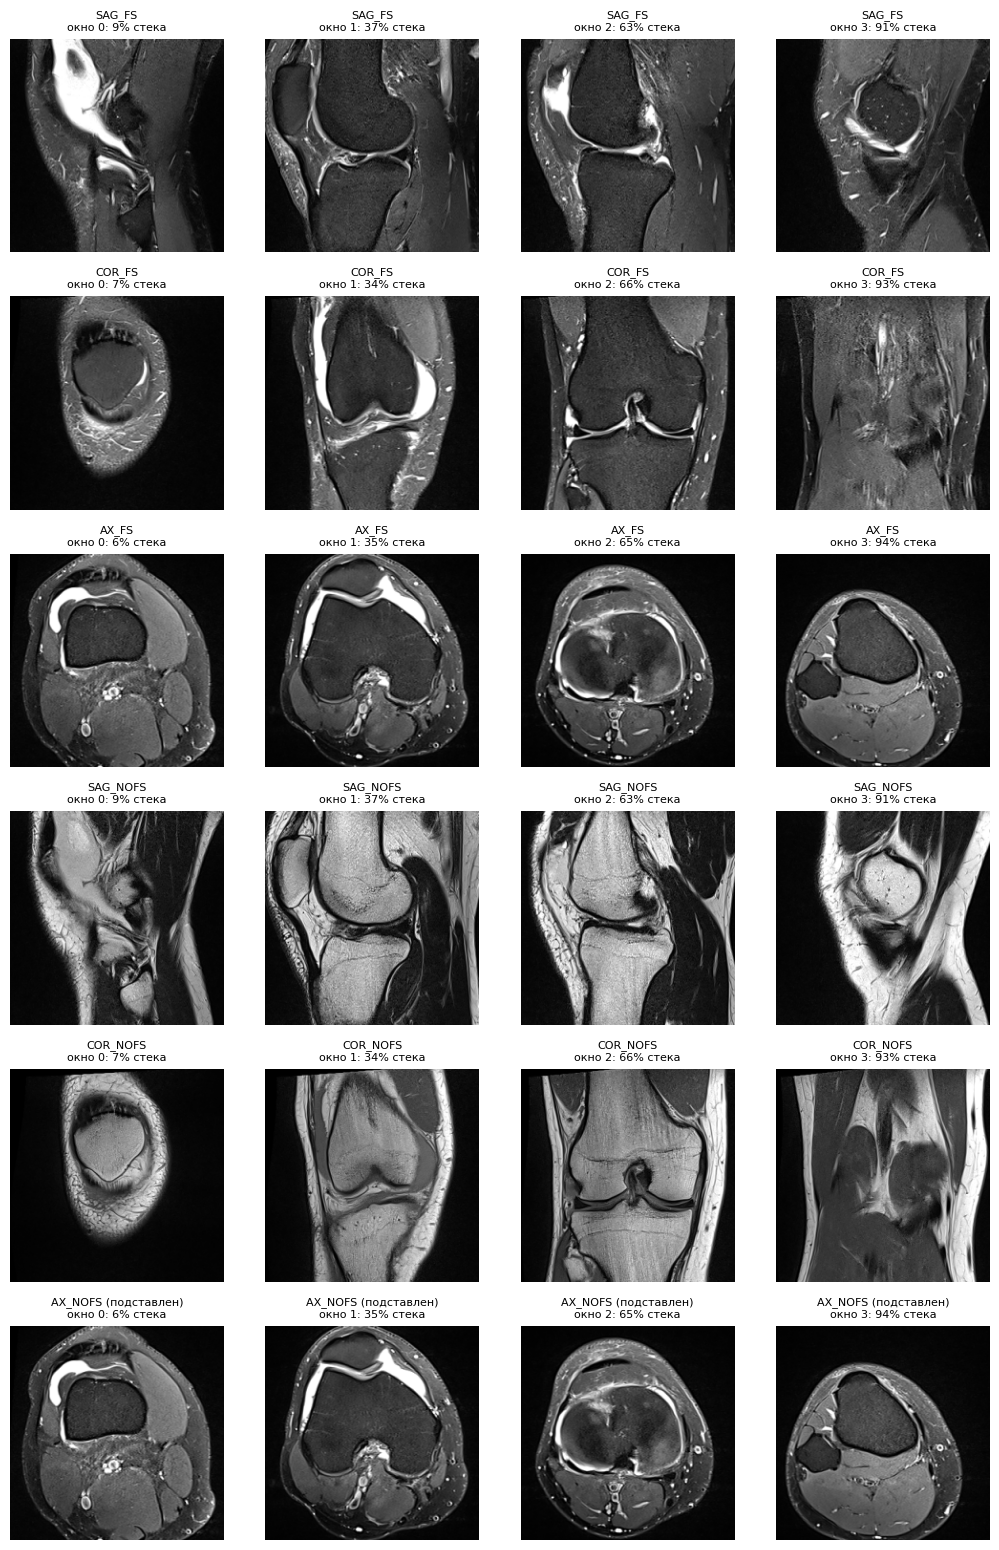

In [24]:
def show_study_windows(slot_table, study):
    g = slot_table[slot_table["StudyInstanceUID"] == study].sort_values("slot")
    fig, axes = plt.subplots(len(g), K_WIN, figsize=(2.6 * K_WIN, 2.6 * len(g)))
    axes = np.atleast_2d(axes)
    for row, r in zip(axes, g.itertuples()):
        out = read_series(r.dir, r.plane)
        for j in range(K_WIN):
            row[j].axis("off")
            if out is not None:
                row[j].imshow(out[0][j * 3 + 1], cmap="gray")
                row[j].set_title(f"{r.slot_name}{' (подставлен)' if r.filled else ''}\n"
                                 f"окно {j}: {out[1][j]:.0%} стека", fontsize=8)
    plt.tight_layout(); plt.show()


if RUN_TRAINING:
    show_study_windows(SLOT_TR, STUDY)

## 6. Кэш: читаем DICOM один раз, учимся много раз

**Главное ускорение по сравнению с v1.** В v1 каждая эпоха заново читала файлы с сетевого диска
Kaggle и заново их декодировала. Здесь всё читается **один раз** в оперативную память:

$$4407\ \text{иссл.} \times 6\ \text{слотов} \times 12\ \text{срезов} \times 224^2 \approx 15\ \text{ГБ (uint8)}$$

Дальше эпоха — это просто копирование из памяти на GPU, без диска.

Результат `build_cache`:
- `studies` — список ID исследований (порядок строк кэша!);
- `cache[N, 6, 12, 224, 224]` — картинки;
- `mask[N, 6]` — 1, если слот заполнен;
- `pos[N, 6, 4]` — где в стеке стоит каждое окно (0 = начало, 1 = конец).

In [25]:
def available_gb():
    try:
        with open("/proc/meminfo") as fh:
            info = dict(l.split(":", 1) for l in fh if ":" in l)
        return int(info["MemAvailable"].split()[0]) / 1024 ** 2
    except Exception:
        return 16.0


def build_cache(slot_table, tag):
    global K_WIN
    studies = sorted(slot_table["StudyInstanceUID"].unique())
    need = len(studies) * N_SLOT * K_WIN * 3 * IMG * IMG / 1024 ** 3
    avail = available_gb()
    log(f"{tag}: кэш займёт {need:.1f} ГБ, свободно {avail:.1f} ГБ")
    while need > CACHE_MAX_SHARE * avail and K_WIN > 2:
        K_WIN -= 1                          # не влезаем — уменьшаем число окон, а не разрешение
        need = len(studies) * N_SLOT * K_WIN * 3 * IMG * IMG / 1024 ** 3
        log(f"  ⚠️ не влезает: K_WIN уменьшен до {K_WIN} ({need:.1f} ГБ)")

    sidx = {s: i for i, s in enumerate(studies)}
    cache = np.zeros((len(studies), N_SLOT, K_WIN * 3, IMG, IMG), np.uint8)
    mask = np.zeros((len(studies), N_SLOT), np.float32)
    pos = np.zeros((len(studies), N_SLOT, K_WIN), np.float32)

    # одна серия может стоять в двух слотах (подстановка) — читаем её один раз
    uniq = slot_table.drop_duplicates("SeriesInstanceUID")[["SeriesInstanceUID", "dir", "plane"]]
    where = slot_table.groupby("SeriesInstanceUID")[["StudyInstanceUID", "slot"]].apply(
        lambda g: list(zip(g["StudyInstanceUID"], g["slot"]))).to_dict()
    jobs = list(uniq.itertuples(index=False))
    log(f"{tag}: читаю {len(jobs)} серий в {SERIES_THREADS} потоков …")
    t0, done = time.time(), 0
    with ThreadPoolExecutor(SERIES_THREADS) as pool:
        for c0 in range(0, len(jobs), 256):
            block = jobs[c0:c0 + 256]
            for j, out in zip(block, pool.map(lambda j: read_series(j.dir, j.plane), block)):
                done += 1
                if out is None:
                    continue
                vol, p = out
                for st, k in where[j.SeriesInstanceUID]:
                    cache[sidx[st], k], pos[sidx[st], k], mask[sidx[st], k] = vol, p, 1.0
            if (c0 // 256) % 10 == 0 or done == len(jobs):
                rate = done / max(time.time() - t0, 1e-6)
                log(f"  {tag}: {done}/{len(jobs)} серий, {rate:.1f} серий/с, "
                    f"осталось ≈{(len(jobs) - done) / max(rate, 1e-6) / 60:.0f} мин")
    log(f"{tag}: заполнено слотов {int(mask.sum())}, серий с битыми срезами: {len(DECODE_FAILED)}")
    gc.collect()
    return studies, cache, mask, pos


if RUN_TRAINING:
    ST_TR, CTR, MTR, PTR = build_cache(SLOT_TR, "train")

[  101.0s] train: кэш займёт 14.8 ГБ, свободно 29.4 ГБ
[  102.1s] train: читаю 21334 серий в 24 потоков …
[  143.7s]   train: 256/21334 серий, 6.2 серий/с, осталось ≈57 мин
[ 1020.0s]   train: 5376/21334 серий, 5.9 серий/с, осталось ≈45 мин
[ 1478.3s]   train: 7936/21334 серий, 5.8 серий/с, осталось ≈39 мин
[ 1907.9s]   train: 10496/21334 серий, 5.8 серий/с, осталось ≈31 мин
[ 2330.1s]   train: 13056/21334 серий, 5.9 серий/с, осталось ≈24 мин
[ 2770.9s]   train: 15616/21334 серий, 5.9 серий/с, осталось ≈16 мин
[ 3180.3s]   train: 18176/21334 серий, 5.9 серий/с, осталось ≈9 мин
[ 3613.5s]   train: 20736/21334 серий, 5.9 серий/с, осталось ≈2 мин
[ 3723.3s]   train: 21334/21334 серий, 5.9 серий/с, осталось ≈0 мин
[ 3723.3s] train: заполнено слотов 26442, серий с битыми срезами: 0


## 7. Метки `Y`, веса `W`, фолды — строго в порядке кэша

⚠️ **Самое опасное место.** Строки кэша идут в порядке `ST_TR` (отсортированные ID), а строки
`train.csv` в другом. Метки переупорядочиваем через `get_indexer`. Если перепутать, получится тот
же класс бага, что в v1: картинки от одних пациентов, метки от других. Поэтому ниже стоят проверки (`assert`).

**Источник меток:** LLM-таблицы, если подключены (вес 1.0), иначе экстрактор (вес по уверенности).
**58 размеченных (`GOLD`)** в обучение не идут (`GOLD_IN_TRAIN = False`). На них каждую эпоху
считается честная метрика `gold`.

**Фолды по хэшу текста заключения.** Одинаковые шаблонные заключения («колено без патологии»)
должны лежать в одном фолде, иначе валидация завышается.

In [26]:
if RUN_TRAINING:
    pos_in_csv = pd.Index(train_df["StudyInstanceUID"]).get_indexer(ST_TR)   # -1 = нет в train.csv
    has = pos_in_csv >= 0
    conf_cols = [t + "__conf" for t in TARGETS]

    Y = np.zeros((len(ST_TR), len(TARGETS)), np.float32)
    W = np.zeros_like(Y)
    Y[has] = LAB[TARGETS].values[pos_in_csv[has]]                      # метки экстрактора
    W[has] = 0.25 + 0.75 * LAB[conf_cols].values[pos_in_csv[has]]
    if LLM is not None:                                                # LLM-метки поверх, где есть
        llm = LLM.reindex(ST_TR)
        ok = llm.notna().all(axis=1).values
        Y[ok], W[ok] = llm.values[ok], 1.0
        log(f"LLM-метки использованы для {ok.sum()} исследований")

    GOLD = np.zeros(len(ST_TR), bool)
    GOLD[has] = gold_mask_df.values[pos_in_csv[has]]
    Y_GOLD = np.zeros_like(Y)
    Y_GOLD[GOLD] = train_df[TARGETS].values[pos_in_csv[GOLD]].astype(np.float32)
    if GOLD_IN_TRAIN:
        Y[GOLD], W[GOLD] = Y_GOLD[GOLD], 3.0

    reports = np.full(len(ST_TR), "", dtype=object)
    reports[has] = train_df["Report"].fillna("").values[pos_in_csv[has]]
    FOLD = np.array([int(hashlib.md5(r.encode()).hexdigest()[:8], 16) % N_FOLDS for r in reports])
    TRAINABLE = np.where((W.sum(1) > 0) & (GOLD_IN_TRAIN | ~GOLD))[0]
    GOLD_IDX = np.where(GOLD)[0]

    # проверки здравого смысла (в v1 все они бы упали)
    assert len(GOLD_IDX) >= 10, "не нашли размеченные исследования — проверьте выравнивание"
    assert (Y[TRAINABLE] > 0.5).mean() > 0.03, "почти нет позитивов — метки не те"
    sid = ST_TR[GOLD_IDX[0]]
    assert np.allclose(Y_GOLD[GOLD_IDX[0]],
                       train_df.set_index("StudyInstanceUID").loc[sid, TARGETS].values.astype(np.float32))
    print("доля «есть» (Y > 0.5) по целям в обучающих данных:")
    display(pd.DataFrame({"Y>0.5": (Y[TRAINABLE] > 0.5).mean(0), "средний W": W[TRAINABLE].mean(0)},
                         index=TARGETS).round(3))
    log(f"учимся на {len(TRAINABLE)} исследованиях, проверяем на {len(GOLD_IDX)} размеченных; "
        f"размеры фолдов: {np.bincount(FOLD[TRAINABLE], minlength=N_FOLDS).tolist()}")

доля «есть» (Y > 0.5) по целям в обучающих данных:


,Y>0.5,средний W
ACL,0.225,0.616
MCL,0.131,0.600
Medial Meniscus,0.418,0.663
Lateral Meniscus,0.193,0.601
Medial OA,0.201,0.421
Lateral OA,0.153,0.402
PF OA,0.296,0.599
Effusion,0.536,0.706
Synovitis,0.339,0.354
Baker's,0.247,0.499


[ 3723.9s] учимся на 4349 исследованиях, проверяем на 58 размеченных; размеры фолдов: [1073, 1110, 1056, 1110]


## 8. Модель: энкодер + «внимание по окнам» (MIL)

Исследование — это «мешок» картинок: до 6 серий × 4 окна = 24 картинки. Метка дана на весь
мешок, а не на конкретную картинку. Такая постановка называется **MIL** (multiple instance learning).

```
каждая картинка [3, 224, 224] ──► DINOv2 (энкодер) ──► вектор 384
          + «какой это слот» (эмбеддинг слота)
          + «где в стеке окно» (эмбеддинг позиции)
все 24 вектора ──► 1 слой трансформера (окна «видят» друг друга)
          ──► для КАЖДОЙ из 12 патологий своё внимание: веса по 24 окнам (softmax)
          ──► взвешенная сумма ──► логит патологии
```

**Зачем своё внимание каждой патологии.** Разрыв ACL виден на 1–2 сагиттальных окнах, артроз
размазан по корональным. Общее среднее размыло бы оба сигнала, а своё внимание позволяет
каждой патологии «смотреть» туда, где её видно.

**Пустые слоты** не прогоняются через энкодер (экономия времени) и исключаются из внимания маской.

**Загрузка весов** сделана со строгой проверкой: если ключи не совпали, будет ошибка.
В v1 `strict=False` молча проглотил бы несовпадение, и сеть училась бы с нуля.

In [27]:
def load_backbone(name, weights_path, img):
    # weights_path=False → пустая архитектура (на инференсе веса придут из чекпойнта фолда)
    kw = dict(num_classes=0)                # num_classes=0 → сеть отдаёт вектор признаков, без головы
    if name.startswith(("vit_", "eva", "beit")):
        kw["img_size"] = img                # у ViT позиционные эмбеддинги зависят от размера входа
    if weights_path is False:
        return timm.create_model(name, pretrained=False, **kw)
    if weights_path and os.path.exists(weights_path):
        m = timm.create_model(name, pretrained=False, **kw)
        sd = torch.load(weights_path, map_location="cpu", weights_only=False)
        for key in ("state_dict", "model"):               # бывают обёртки {"model": {...}}
            if isinstance(sd, dict) and key in sd and isinstance(sd[key], dict):
                sd = sd[key]
        sd = {k.removeprefix("module.").removeprefix("model."): v for k, v in sd.items()}
        sd = {k: v for k, v in sd.items() if not k.startswith(("head.fc.", "fc.", "classifier."))
              and not (k.startswith("head.") and name.startswith("vit_"))}
        if "pos_embed" in sd and hasattr(m, "pos_embed") and sd["pos_embed"].shape != m.pos_embed.shape:
            # веса DINOv2 сохранены под 518px; под наш IMG интерполируем позиционные эмбеддинги
            from timm.layers import resample_abs_pos_embed
            sd["pos_embed"] = resample_abs_pos_embed(sd["pos_embed"], new_size=m.patch_embed.grid_size,
                                                     num_prefix_tokens=m.num_prefix_tokens)
        missing, unexpected = m.load_state_dict(sd, strict=False)
        assert not missing and not unexpected, (
            f"веса не подходят к {name}: missing={missing[:5]} unexpected={unexpected[:5]}")
        log(f"энкодер {name}: веса из файла, все ключи совпали")
        return m
    log(f"энкодер {name}: файла весов нет — скачиваю через timm (нужен Internet)")
    return timm.create_model(name, pretrained=True, **kw)


def set_trainable(bb, n_last):
    # всё заморозить, потом открыть «последнюю часть» сети
    for p in bb.parameters():
        p.requires_grad = False
    if hasattr(bb, "blocks"):               # ViT: последние n_last блоков + финальная нормализация
        parts = list(bb.blocks)[-n_last:] + [getattr(bb, "norm", None)]
    elif hasattr(bb, "stages"):             # ConvNeXt и похожие CNN: две последние стадии + голова
        parts = list(bb.stages)[-2:] + [getattr(bb, "head", None), getattr(bb, "norm_pre", None)]
    else:
        parts = [bb]
    for part in parts:
        if part is not None:
            for p in part.parameters():
                p.requires_grad = True


class StudyMIL(nn.Module):
    def __init__(self, backbone=BACKBONE, weights=WEIGHTS_PATH, unfreeze_last=UNFREEZE_LAST,
                 hidden=HIDDEN, tf_depth=TF_DEPTH):
        super().__init__()
        self.backbone = load_backbone(backbone, weights, IMG)
        set_trainable(self.backbone, unfreeze_last)
        d = self.backbone.num_features
        self.proj = nn.Sequential(nn.Dropout(0.1), nn.Linear(d, hidden), nn.LayerNorm(hidden))
        self.slot_emb = nn.Embedding(N_SLOT, hidden)            # «это сагиттальная FS» и т.п.
        self.pos_emb = nn.Sequential(nn.Linear(1, hidden), nn.GELU(), nn.Linear(hidden, hidden))
        if tf_depth:
            layer = nn.TransformerEncoderLayer(hidden, 4, hidden * 2, dropout=0.1,
                                               batch_first=True, norm_first=True)
            self.tf = nn.TransformerEncoder(layer, tf_depth, enable_nested_tensor=False)
        else:
            self.tf = None
        # внимание: для каждого окна 12 чисел «насколько это окно важно для патологии c»
        self.att = nn.Sequential(nn.Linear(hidden, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, len(TARGETS)))
        self.cls_w = nn.Parameter(torch.randn(len(TARGETS), hidden) * 0.02)   # свой выход у каждой патологии
        self.cls_b = nn.Parameter(torch.zeros(len(TARGETS)))
        # нормализация ImageNet: энкодер учили на входах около N(0, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x, mask, pos):
        # x: uint8 [B, S, K, 3, H, W]   mask: [B, S]   pos: [B, S, K]   →   логиты [B, 12]
        B, S, K = x.shape[:3]
        keep = mask.reshape(-1) > 0.5                          # какие (исследование, слот) есть
        feat = None
        if keep.any():
            xs = x.reshape(B * S, K, *x.shape[3:])[keep].flatten(0, 1)   # только существующие картинки
            xs = (xs.float() / 255.0 - self.mean) / self.std
            f = self.backbone(xs)                              # [n_картинок, d]
            feat = f.new_zeros(B * S, K, f.shape[-1])
            feat[keep] = f.view(-1, K, f.shape[-1])
        else:
            feat = x.new_zeros((B * S, K, self.backbone.num_features), dtype=torch.float32)
        h = self.proj(feat.view(B, S, K, -1))
        h = h + self.slot_emb(torch.arange(S, device=x.device)).view(1, S, 1, -1)
        h = h + self.pos_emb(pos.unsqueeze(-1).to(h.dtype))
        h = h.view(B, S * K, -1)                               # все окна исследования в одну «строку»
        pad = ~(mask > 0.5).unsqueeze(-1).expand(B, S, K).reshape(B, S * K)   # True = окна нет
        pad = pad & ~pad.all(1, keepdim=True)                  # исследование без серий: не маскируем всё
        if self.tf is not None:
            h = self.tf(h, src_key_padding_mask=pad)
        a = self.att(h).float().masked_fill(pad.unsqueeze(-1), -1e4).softmax(1)   # [B, окна, 12]
        pooled = torch.einsum("btc,btd->bcd", a.to(h.dtype), h)                   # [B, 12, hidden]
        return (pooled * self.cls_w).sum(-1) + self.cls_b


# быстрая проверка формы на случайном входе
_m = StudyMIL().to(DEV).eval()
with torch.no_grad():
    _x = torch.randint(0, 255, (2, N_SLOT, K_WIN, 3, IMG, IMG), dtype=torch.uint8, device=DEV)
    _mk = torch.ones(2, N_SLOT, device=DEV); _mk[1, 2:] = 0
    _out = _m(_x, _mk, torch.rand(2, N_SLOT, K_WIN, device=DEV))
_tr = sum(p.numel() for p in _m.parameters() if p.requires_grad)
log(f"выход {tuple(_out.shape)}; обучаемых параметров {_tr / 1e6:.1f}M из "
    f"{sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
assert _out.shape == (2, len(TARGETS)) and torch.isfinite(_out).all()
del _m, _out, _x

[ 3723.9s] энкодер vit_small_patch14_dinov2.lvd142m: файла весов нет — скачиваю через timm (нужен Internet)


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[ 3729.2s] выход (2, 12); обучаемых параметров 11.4M из 22.4M


## 9. Инструменты обучения

**`augment`.** Случайные искажения, которые **не меняют диагноз**:
- поворот ±10°, сдвиг ±6%, зум только внутрь (до +10%);
- контраст (гамма) и яркость.

Вертикальный флип **запрещён**: бедро и голень поменялись бы местами, а на этом определены OA-цели.

**`mirror` — зеркало колена (идея из ноутбука 0.958).** Левое колено в зеркале выглядит как
правое. Медиальная сторона остаётся медиальной, поэтому метки **не меняются**. Как отражать:
- корональные и аксиальные снимки — по горизонтали;
- сагиттальные — разворачиваем **порядок срезов**: стек идёт «от медиального края к
  латеральному» или наоборот, а сам срез при отражении не меняется.

В обучении зеркалим 50% исследований: модель видит и «левые», и «правые» колени. На тесте
усредняем обычный и зеркальный вид (TTA): два «взгляда» вместо одного.

**`rank_loss`.** AUC — это доля правильно упорядоченных пар «больной выше здорового». В батче для
каждой патологии берём пары (уверенно есть, уверенно нет) и штрафуем, если «есть» получил оценку ниже.

**`Ema`.** Держит «среднее» весов за последние ~300 шагов. Такая модель стабильнее, чем веса
на любом отдельном шаге.

**`predict`.** Все `K_WIN` окон, плюс зеркальный вид, если `TTA_MIRROR`.

In [28]:
def augment(x):
    # x: uint8 [..., 3, H, W] на GPU → та же форма; своё случайное искажение на каждую картинку
    lead = x.shape[:-3]
    y = x.reshape(-1, *x.shape[-3:]).float() / 255.0
    n, dev = y.shape[0], y.device
    rot = (torch.rand(n, device=dev) - 0.5) * 2 * math.radians(AUG_ROT_DEG)
    sc = 1.0 + torch.rand(n, device=dev) * AUG_SCALE            # > 1 → зум внутрь
    tx = (torch.rand(n, device=dev) - 0.5) * 2 * AUG_SHIFT
    ty = (torch.rand(n, device=dev) - 0.5) * 2 * AUG_SHIFT
    cos, sin = torch.cos(rot) / sc, torch.sin(rot) / sc
    theta = torch.zeros(n, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos, -sin, tx
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin, cos, ty
    grid = F.affine_grid(theta, y.shape, align_corners=False)
    y = F.grid_sample(y, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    gamma = torch.exp((torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 2 * AUG_GAMMA)   # контраст
    gain = 1.0 + (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 2 * AUG_GAIN          # яркость
    y = (y.clamp_min(1e-4) ** gamma * gain).clamp(0, 1)
    return (y * 255).round().reshape(*lead, *y.shape[-3:]).to(torch.uint8)


def mirror(x, pos):
    # зеркало колена: x [B, S, K, 3, H, W], pos [B, S, K] → то же
    x, pos = x.clone(), pos.clone()
    for s in range(x.shape[1]):
        if s in SAG_SLOTS:
            x[:, s] = x[:, s].flip(1).flip(2)        # обратный порядок окон и срезов внутри окна
            pos[:, s] = 1 - pos[:, s].flip(-1)
        else:
            x[:, s] = x[:, s].flip(-1)               # отражение по горизонтали
    return x, pos


def rank_loss(z, y, w):
    parts = []
    for j in range(z.shape[1]):
        zp = z[(y[:, j] > RANK_POS) & (w[:, j] > 0), j]
        zn = z[(y[:, j] < RANK_NEG) & (w[:, j] > 0), j]
        if len(zp) and len(zn):
            parts.append(F.softplus(-(zp[:, None] - zn[None, :])).mean())
    return torch.stack(parts).mean() if parts else z.new_tensor(0.0)


class Ema:
    def __init__(self, model, decay):
        self.decay, self.step = decay, 0
        self.model = deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1.0 + self.step) / (10.0 + self.step))   # разогрев: сначала быстро
        src = model.state_dict()
        for k, v in self.model.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src[k].detach(), alpha=1.0 - d)
            else:
                v.copy_(src[k])


def to_batch(cache, mask, pos, sel, win=None):
    # строки кэша → тензоры на GPU нужной формы; win — какие окна взять (None = все)
    x = torch.from_numpy(cache[sel]).view(len(sel), N_SLOT, -1, 3, IMG, IMG)
    p = torch.from_numpy(pos[sel])
    if win is not None:
        x, p = x[:, :, win], p[:, :, win]
    return (x.to(DEV, non_blocking=True), torch.from_numpy(mask[sel]).to(DEV), p.to(DEV))


@torch.no_grad()
def predict(model, cache, mask, pos, idx, tta_mirror=TTA_MIRROR):
    # → вероятности [len(idx), 12]
    model.eval()
    out = []
    for b in range(0, len(idx), EVAL_BATCH):
        sel = np.sort(idx[b:b + EVAL_BATCH])
        order = np.argsort(np.argsort(idx[b:b + EVAL_BATCH]))   # вернуть исходный порядок
        x, m, p = to_batch(cache, mask, pos, sel)
        with torch.autocast("cuda", enabled=USE_AMP):
            prob = torch.sigmoid(model(x, m, p).float())
            if tta_mirror:
                xm, pm = mirror(x, p)
                prob = 0.5 * (prob + torch.sigmoid(model(xm, m, pm).float()))
        out.append(prob.cpu().numpy()[order])
    return np.concatenate(out) if out else np.zeros((0, len(TARGETS)), np.float32)


def macro_auc(y, p):
    # метрика соревнования: среднее AUC по колонкам, где есть оба класса
    return float(np.nanmean([roc_auc_score(y[:, j], p[:, j]) if 0 < y[:, j].sum() < len(y)
                             else np.nan for j in range(y.shape[1])]))


# самопроверки
_a = augment(torch.randint(0, 255, (2, 3, 3, 32, 32), dtype=torch.uint8))
assert _a.shape == (2, 3, 3, 32, 32) and _a.dtype == torch.uint8
_x = torch.arange(N_SLOT * 2 * 3 * 2 * 2, dtype=torch.float32).view(1, N_SLOT, 2, 3, 2, 2)
_p = torch.tensor([[[0.1, 0.9]] * N_SLOT])
_xm, _pm = mirror(*mirror(_x, _p))
assert torch.equal(_xm, _x) and torch.allclose(_pm, _p), "зеркало дважды должно давать исходник"
assert rank_loss(torch.tensor([[2.], [-2.]]), torch.tensor([[1.], [0.]]), torch.ones(2, 1)) < \
       rank_loss(torch.tensor([[-2.], [2.]]), torch.tensor([[1.], [0.]]), torch.ones(2, 1))
log("augment, mirror и rank_loss прошли самопроверку")

[ 3729.4s] augment, mirror и rank_loss прошли самопроверку


## 10. Обучение

Каждую эпоху печатаются две метрики:
- **`derived`**: macro-AUC на валидационном фолде против меток из текста (Y > 0.5).
  ~1100 исследований, но метки приблизительные;
- **`gold`**: macro-AUC на **всех 58** вручную размеченных (они не участвуют в обучении).
  Это ближе всего к тому, что считает Kaggle, но 58 — мало, так что шум ±0.03–0.05.

**Лучшая эпоха** выбирается по `min(derived, gold)`: эпоха считается лучше, только если лучше
её **слабейшая** метрика.

**Что происходит в одном шаге:**
1. берём 8 исследований и 2 случайных окна из 4 в каждой серии (`K_TRAIN`);
2. аугментация + зеркало для половины исследований;
3. модель → 12 логитов → `BCE × W` (+ ranking loss) → шаг оптимизатора → шаг LR → обновление EMA.

**Скорость обучения (LR):** `OneCycleLR` — первые 15% шагов LR растёт, потом плавно падает.
Энкодер учится в ~60 раз медленнее головы (`LR_BACKBONE` против `LR_HEAD`).

In [29]:
def train_fold(k):
    tr = TRAINABLE[FOLD[TRAINABLE] != k]
    va = TRAINABLE[FOLD[TRAINABLE] == k]
    yv = (Y[va] > 0.5).astype(int)
    log(f"=== фолд {k}: учимся на {len(tr)}, проверяем на {len(va)} (+ {len(GOLD_IDX)} размеченных) ===")
    assert len(tr) >= BATCH_STUDIES and len(va) > 0, "пустой фолд — проверьте FOLD"

    seed_everything(SEED + k)
    model = StudyMIL().to(DEV)
    ema = Ema(model, EMA_DECAY) if EMA_DECAY > 0 else None
    bb_params = [p for p in model.backbone.parameters() if p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    opt = torch.optim.AdamW([{"params": bb_params, "lr": LR_BACKBONE},
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    steps = EPOCHS * (len(tr) // BATCH_STUDIES)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACKBONE, LR_HEAD],
                                                total_steps=steps, pct_start=PCT_START)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best, best_state, hist = -1.0, None, []
    for ep in range(EPOCHS):
        model.train()
        perm = np.random.permutation(tr)
        tot, n, t_ep = 0.0, 0, time.time()
        for b in range(0, len(perm) - BATCH_STUDIES + 1, BATCH_STUDIES):
            sel = np.sort(perm[b:b + BATCH_STUDIES])          # сортировка ускоряет чтение из кэша
            win = np.sort(np.random.choice(K_WIN, min(K_TRAIN, K_WIN), replace=False))
            x, m, p = to_batch(CTR, MTR, PTR, sel, win)
            x = augment(x)
            flip = torch.rand(len(sel), device=DEV) < MIRROR_P
            if flip.any():
                x[flip], p[flip] = mirror(x[flip], p[flip])
            y = torch.from_numpy(Y[sel]).to(DEV)
            w = torch.from_numpy(W[sel]).to(DEV)
            with torch.autocast("cuda", enabled=USE_AMP):
                z = model(x, m, p)
                loss = (F.binary_cross_entropy_with_logits(z.float(), y, reduction="none") * w).mean()
                if RANK_LOSS_W > 0:
                    loss = loss + RANK_LOSS_W * rank_loss(z.float(), y, w)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            if ema is not None:
                ema.update(model)
            tot += loss.item(); n += 1

        ev = ema.model if ema is not None else model
        d = macro_auc(yv, predict(ev, CTR, MTR, PTR, va, tta_mirror=False))
        g = macro_auc(Y_GOLD[GOLD_IDX].astype(int), predict(ev, CTR, MTR, PTR, GOLD_IDX))
        score = min(d, g)
        hist.append({"fold": k, "epoch": ep + 1, "loss": tot / max(n, 1), "derived": d, "gold": g})
        flag = ""
        if score > best:
            best, flag = score, "  ← лучшая"
            best_state = {kk: v.detach().cpu().clone() for kk, v in ev.state_dict().items()}
        log(f"фолд {k} эпоха {ep + 1}/{EPOCHS}  loss {tot / max(n, 1):.4f}  derived {d:.4f}  "
            f"gold {g:.4f}  ({time.time() - t_ep:.0f}s){flag}")
        if time.time() - T0 > TIME_BUDGET:
            log("время вышло внутри фолда")
            break

    model.load_state_dict(best_state)
    gold_pred = predict(model, CTR, MTR, PTR, GOLD_IDX)
    del opt, sched, scaler, ema
    return model, best_state, gold_pred, hist

[ 3729.4s] === фолд 0: учимся на 3276, проверяем на 1073 (+ 58 размеченных) ===
[ 3729.4s] энкодер vit_small_patch14_dinov2.lvd142m: файла весов нет — скачиваю через timm (нужен Internet)
[ 3887.7s] фолд 0 эпоха 1/10  loss 0.3844  derived 0.7058  gold 0.7062  (158s)  ← лучшая
[ 4053.1s] фолд 0 эпоха 2/10  loss 0.3716  derived 0.7417  gold 0.7221  (165s)  ← лучшая
[ 4218.5s] фолд 0 эпоха 3/10  loss 0.3641  derived 0.7635  gold 0.7549  (165s)  ← лучшая
[ 4384.0s] фолд 0 эпоха 4/10  loss 0.3584  derived 0.7800  gold 0.7864  (165s)  ← лучшая
[ 4549.0s] фолд 0 эпоха 5/10  loss 0.3542  derived 0.7870  gold 0.7887  (165s)  ← лучшая
[ 4714.4s] фолд 0 эпоха 6/10  loss 0.3492  derived 0.7922  gold 0.7951  (165s)  ← лучшая
[ 4879.5s] фолд 0 эпоха 7/10  loss 0.3440  derived 0.7950  gold 0.7938  (165s)  ← лучшая
[ 5044.8s] фолд 0 эпоха 8/10  loss 0.3405  derived 0.7972  gold 0.7960  (165s)  ← лучшая
[ 5210.0s] фолд 0 эпоха 9/10  loss 0.3371  derived 0.7984  gold 0.7971  (165s)  ← лучшая
[ 5375.1s] 

,gold AUC по целям
ACL,0.746
MCL,0.692
Medial Meniscus,0.672
Lateral Meniscus,0.821
Medial OA,0.905
Lateral OA,0.826
PF OA,0.741
Effusion,0.865
Synovitis,0.676
Baker's,0.902


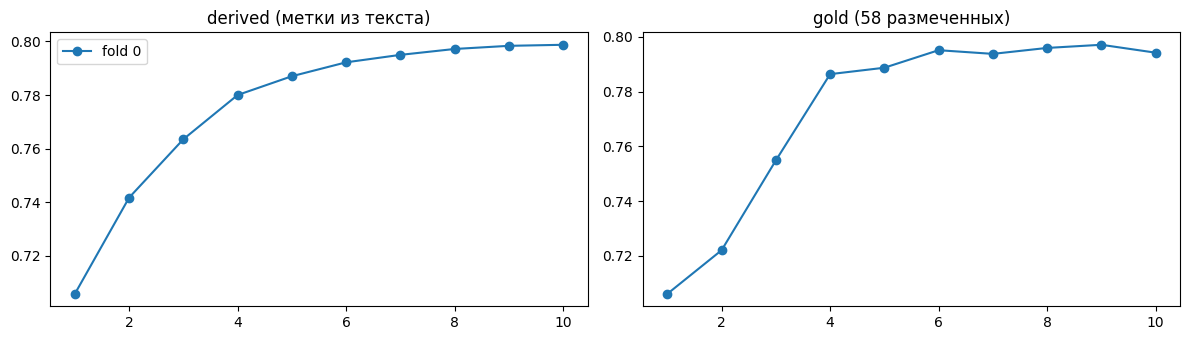

In [30]:
if RUN_TRAINING:
    WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
    HIST, GOLD_PREDS = [], []
    for k in FOLDS_TO_RUN:
        t_fold = time.time()
        model, state, gp, hist = train_fold(k)
        HIST += hist
        GOLD_PREDS.append(pd.DataFrame(gp).rank(pct=True).values)
        torch.save({"model": state, "config": {"BACKBONE": BACKBONE, "IMG": IMG, "CROP_MM": CROP_MM,
                    "K_WIN": K_WIN, "WIN_BAND": WIN_BAND, "UNFREEZE_LAST": UNFREEZE_LAST,
                    "HIDDEN": HIDDEN, "TF_DEPTH": TF_DEPTH}}, WEIGHTS_DIR / f"fold{k}.pth")
        fold_time = time.time() - t_fold
        log(f"фолд {k} готов за {fold_time / 60:.1f} мин → {WEIGHTS_DIR / f'fold{k}.pth'}")
        del model, state
        gc.collect(); torch.cuda.empty_cache()
        if time.time() - T0 + 1.15 * fold_time > TIME_BUDGET:
            log("следующий фолд не успеет — останавливаемся")
            break

    y_gold = Y_GOLD[GOLD_IDX].astype(int)
    ens = np.mean(GOLD_PREDS, axis=0)
    log(f"ансамбль {len(GOLD_PREDS)} фолд(ов) на {len(GOLD_IDX)} размеченных: gold macro-AUC = {macro_auc(y_gold, ens):.4f}")
    per_t = [roc_auc_score(y_gold[:, j], ens[:, j]) if 0 < y_gold[:, j].sum() < len(y_gold) else np.nan
             for j in range(len(TARGETS))]
    display(pd.Series(per_t, index=TARGETS, name="gold AUC по целям").round(3).to_frame())

    h = pd.DataFrame(HIST)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for f_, gdf in h.groupby("fold"):
        ax[0].plot(gdf.epoch, gdf.derived, "o-", label=f"fold {f_}")
        ax[1].plot(gdf.epoch, gdf.gold, "o-", label=f"fold {f_}")
    ax[0].set_title("derived (метки из текста)"); ax[1].set_title("gold (58 размеченных)")
    ax[0].legend(); plt.tight_layout(); plt.show()

## 11. Предсказание test и `submission.csv`

1. Освобождаем train-кэш (~15 ГБ).
2. Для test всё то же самое: слоты → чтение серий → кэш, **с теми же настройками**.
3. Каждый фолд предсказывает test (обычный + зеркальный вид).
4. Предсказания фолдов **переводим в ранги** и усредняем. AUC читает только порядок, а у разных
   моделей разная «уверенность»: без рангов самая уверенная модель перетянула бы среднее.
5. Submission **склеиваем с `test.csv` по `StudyInstanceUID`**, а не по позиции строки (как в v1).
   Исследование без снимков получает 0.5.

In [31]:
# сначала пишем «пустой» сабмит со всеми 0.5: если дальше что-то упадёт, файл всё равно будет
_bench = test_df[["StudyInstanceUID"]].copy()
for _t in TARGETS:
    _bench[_t] = 0.5
_bench.to_csv(WORK / "submission.csv", index=False)

for _name in ("CTR", "MTR", "PTR"):
    globals().pop(_name, None)
gc.collect()

SLOT_TE = build_slot_table(test_series, "test_series")
ST_TE, CTE, MTE, PTE = build_cache(SLOT_TE, "test")

fold_files = sorted(WEIGHTS_DIR.glob("fold*.pth"))
assert fold_files, f"нет весов в {WEIGHTS_DIR}"
ranks = []
for fp in fold_files:
    ck = torch.load(fp, map_location="cpu", weights_only=False)
    cfg = ck["config"]
    assert (cfg["IMG"], cfg["CROP_MM"], cfg["K_WIN"]) == (IMG, CROP_MM, K_WIN), \
        f"{fp.name} обучен с другой подготовкой картинок: {cfg}"
    model = StudyMIL(backbone=cfg["BACKBONE"], weights=False, unfreeze_last=cfg["UNFREEZE_LAST"],
                     hidden=cfg["HIDDEN"], tf_depth=cfg["TF_DEPTH"]).to(DEV)
    model.load_state_dict(ck["model"])
    pr = predict(model, CTE, MTE, PTE, np.arange(len(ST_TE)))
    ranks.append(pd.DataFrame(pr).rank(pct=True).values)
    log(f"{fp.name}: предсказано {len(ST_TE)} исследований")
    del model, ck
    gc.collect()

sub = pd.DataFrame(np.mean(ranks, axis=0), columns=TARGETS)
sub.insert(0, "StudyInstanceUID", ST_TE)
sub = test_df[["StudyInstanceUID"]].merge(sub, on="StudyInstanceUID", how="left")
sub[TARGETS] = sub[TARGETS].fillna(0.5)
sub.to_csv(WORK / "submission.csv", index=False)
log(f"submission.csv: {sub.shape}, пустых значений: {int(sub[TARGETS].isna().sum().sum())}")
display(sub.head())

[ 5381.6s] test: кэш займёт 0.0 ГБ, свободно 28.2 ГБ
[ 5381.6s] test: читаю 13 серий в 24 потоков …
[ 5388.5s]   test: 13/13 серий, 1.9 серий/с, осталось ≈0 мин
[ 5388.6s] test: заполнено слотов 18, серий с битыми срезами: 0
[ 5389.4s] fold0.pth: предсказано 3 исследований
[ 5389.7s] submission.csv: (3, 13), пустых значений: 0


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.666667,0.333333,0.333333,0.666667,0.333333,1.000000,0.333333,0.333333,0.666667,1.000000,0.333333,0.333333
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,1.000000,1.000000,1.000000,1.000000,1.000000,0.666667,1.000000,1.000000,1.000000,0.666667,1.000000,1.000000
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.333333,0.333333,0.666667,0.666667


## 12. ⏱ Сколько это идёт и почему v1 был таким медленным

### Почему v1 шёл часами

| что делал v1 | сколько это стоит |
|---|---|
| для **каждого** исследования читал заголовки **всех** файлов всех серий (~650 тыс. файлов по сети), чтобы найти «центральный срез» | десятки минут на первый проход |
| каждую эпоху **заново** читал 3 DICOM на исследование с сетевого диска и декодировал их (`num_workers=2`) | диск и CPU — узкое место, GPU простаивает |
| ViT-B (86M) в **float32**, без смешанной точности | в ~2 раза медленнее, чем float16 |
| 5 фолдов × 10 эпох, и каждая эпоха включает пункт 2 | итого: часы, и ни одного законченного прогона |

### Что сделано здесь

| приём | эффект |
|---|---|
| **кэш в памяти**: каждый нужный срез читается и декодируется **один раз** | эпоха — только память → GPU |
| читаем только 12 нужных срезов из ≤6 выбранных серий, в 24 потока | декодирование ~в 10 раз меньше файлов |
| ViT-**S** (22M), половина блоков заморожена, AMP float16 | шаг обучения в ~4–6 раз дешевле |
| пустые слоты не идут в энкодер; в обучении 2 окна из 4 | ещё ~2× меньше картинок на шаг |

### Ориентиры на Kaggle GPU (T4/P100), примерно

| этап | время |
|---|---|
| часть A (смотрим данные) | 2–5 мин |
| подсчёт файлов + чтение train в кэш | 40–90 мин (зависит от скорости диска Kaggle в этот день) |
| одна эпоха (≈3300 исследований) + проверка | ≈3–5 мин |
| один фолд (10 эпох) | ≈35–50 мин |
| **первый запуск, `FOLDS_TO_RUN = [0]`** | **≈1.5–2.5 ч** |
| все 4 фолда | ≈4–5.5 ч |
| только инференс (`RUN_TRAINING = False`) на скрытом test | ≈20–40 мин |

Точное время чтения будет видно в логе `build_cache`: там печатается скорость (серий/с) и
сколько осталось.

## 13. Что дальше: по одному изменению за раз

1. **Подключить LLM-таблицы меток** (раздел 3.2). Самый сильный рычаг: потолок модели — это качество меток.
2. **Обучение отдельно от сабмита.** Обучили → сохранили `/kaggle/working/weights` как Dataset →
   в ноутбуке для сабмита `RUN_TRAINING = False` и `WEIGHTS_DIR` указывает на этот датасет.
   Сабмит тогда занимает ~30 мин вместо часов.
3. **`IMG = 336`** (0.42 мм/пиксель): тонкие разрывы мениска лучше переживают ресайз. Кэш вырастет
   в 2.25 раза. Ячейка сама уменьшит `K_WIN`, если не влезет.
4. **Другой энкодер для ансамбля:** CNN (`convnext_tiny.fb_in22k`) или ваш ViT-B. Разные архитектуры
   ошибаются по-разному, и среднее рангов выигрывает.
5. Больше окон (`K_WIN = 6`) — если хватит памяти.

**Чего не делать:**
- вертикальный флип (бедро ↔ голень);
- label smoothing (метки уже мягкие);
- `pos_weight` и пороги (AUC от них не зависит).